[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol11_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 11: Modele în timp continuu

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza, Academia de Studii Economice din București.*

- Problemele **[Rezolvat]** conțin rezolvarea completă; problemele **[Propus]** le rezolvați dumneavoastră.
- Partea A: derivări (A1–A9); Partea B: estimare și inferență (B1–B9); Partea C: întrebări deschise (C2, C3; C1 analizează un răspuns Artificial Intelligence (AI) intenționat greșit).

> Rezolvările se discută la seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_11'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261018T165355-085c1c


## Exerciții

[A4](#exercise-a4) · [A5](#exercise-a5) · [A6](#exercise-a6) · [A2](#exercise-a2) · [A7](#exercise-a7) · [A8](#exercise-a8) · [A3](#exercise-a3) · [A9](#exercise-a9) · [A1](#exercise-a1) · [B4](#exercise-b4) · [B1](#exercise-b1) · [B3](#exercise-b3) · [B2](#exercise-b2) · [B2 Extended](#exercise-b2-extended) · [B6](#exercise-b6) · [B5](#exercise-b5) · [B5 Extended](#exercise-b5-extended) · [B7](#exercise-b7) · [B8](#exercise-b8) · [B8 Extended](#exercise-b8-extended) · [B9](#exercise-b9) · [C2](#exercise-c2) · [C3](#exercise-c3)

In [ ]:
import os
import re
import io
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
import warnings
warnings.filterwarnings('ignore')

## Stil și funcții ajutătoare

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Brand colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
MODEL_COL = {'Data': MainBlue, 'GBM': Orange, 'Merton': Purple, 'Heston': Forest}

HERE = '.'
CHART_DIR = '.'
SEED = 42
DT = 1 / 252


def save_fig(name):
    """Save the figure as a transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """A single legend for a multi-panel figure, below the figure."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            h, l = ax.get_legend_handles_labels()
            for hh, ll in zip(h, l):
                if ll not in labels and not ll.startswith('_'):
                    handles.append(hh)
                    labels.append(ll)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    if isinstance(x, np.ndarray):
        return [jsonable(v) for v in x.tolist()]
    if isinstance(x, pd.Timestamp):
        return str(x.date())
    return x


import tempfile
# cu SAVE_TO_DRIVE = True (celula de la inceput) graficele si tabelele merg in OUT_DIR din Drive; altfel intr-un folder temporar
HERE = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(name):
    """Afiseaza figura; cu SAVE_TO_DRIVE = True o salveaza si ca PNG in OUT_DIR."""
    if globals().get('SAVE_TO_DRIVE'):
        plt.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close()

## Date

- Închideri zilnice pînă la 18 septembrie 2026: S&P 500 (1990–2026), Bucharest Exchange Trading (BET) (2000–2026), Bitcoin (2014–2026), Cboe Volatility Index (VIX) (1990–2026).
- Randamentul titlurilor de stat SUA pe 3 luni (seria Federal Reserve Economic Data (FRED) DTB3), 1954–2026.
- Indici bursieri: doar zilele lucrătoare, fără cotațiile inerte (închidere neschimbată și nicio variație în cursul zilei), cu randamentele zero reale păstrate; Bitcoin: 7 zile din 7; randamente logaritmice zilnice, timpul în ani.

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, label, type, start date)
MARKETS = {
    'sp500':  ('GSPC.INDX',  'S&P 500',                  'index',  '1990-01-01'),
    'bet':    ('BET',        'BET',                      'index',  '2000-01-01'),
    'btc':    ('BTC-USD.CC', 'Bitcoin',                  'crypto', '2014-09-17'),
    'eurron': ('REF:EUR',    'EUR/RON (reference rate)', 'fx',     '2005-07-01'),
}
LABELS = {k: v[1] for k, v in MARKETS.items()}

_CACHE = {}


def read_market(symbol):
    """Read the daily price file of one symbol (local copy if present, otherwise GitHub)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official RON reference rate (annual NBR XML archives)."""
    key = ('bnr', currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def read_fred(series, start='1954-01-01', end=END):
    """Daily FRED series (Federal Reserve Bank of St. Louis), in original units."""
    key = ('fred', series, start, end)
    if key in _CACHE:
        return _CACHE[key]
    url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}'
    for attempt in range(4):
        try:
            raw = urllib.request.urlopen(url, timeout=120).read().decode()
            break
        except OSError:
            if attempt == 3:
                raise
    df = pd.read_csv(io.StringIO(raw), index_col=0, parse_dates=True, na_values='.')
    s = pd.to_numeric(df.iloc[:, 0], errors='coerce').dropna().loc[start:end].rename(series)
    _CACHE[key] = s
    return s


def load_close(name, start=None, end=END):
    """Daily price, cleaned with the chapter conventions."""
    symbol, _, kind, start0 = MARKETS[name]
    start = start or start0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    d = read_market(symbol).loc[start:end]
    d = d[d['close'] > 0].dropna(subset=['close'])
    if kind != 'crypto':
        d = d[d.index.dayofweek < 5]          # no weekend quotes
    s = d['close']
    if kind == 'index':
        # stale quote: unchanged close and no intraday range (or high/low unavailable)
        no_range = (d['high'] <= d['low']) if {'high', 'low'} <= set(d.columns) else pd.Series(True, index=d.index)
        s = s[~((s.diff() == 0) & no_range)]
    return s.rename(name)


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


def periods_per_year(r):
    """Actual frequency: average number of observations per calendar year."""
    return len(r) / ((r.index[-1] - r.index[0]).days / 365.25)


def load_vix(start='1990-01-01', end=END):
    """The VIX index (CBOE), daily close, in annualised volatility points (%)."""
    s = read_market('VIX.INDX')['close'].loc[start:end]
    s = s[(s > 0) & (s.index.dayofweek < 5)].dropna()
    return s.rename('vix')


# daily log returns (not in %), each series on its own calendar
rets = {k: log_returns(k) for k in ['sp500', 'bet', 'btc']}
DTS = {'sp500': 1 / 252, 'bet': 1 / 252, 'btc': 1 / 365}
for k, r in rets.items():
    print(f'{LABELS[k]:26s}', r.index[0].date(), '->', r.index[-1].date(), len(r), 'obs')

S&P 500                    1990-01-03 -> 2026-09-18 9245 obs
BET                        2000-01-06 -> 2026-09-18 6670 obs
Bitcoin                    2014-09-18 -> 2026-09-18 4384 obs


## Modele în timp continuu

- Mișcarea browniană, variația pătratică, sumele Itô și Stratonovich; Euler–Maruyama și Milstein.
- Mișcarea browniană geometrică (Geometric Brownian Motion (GBM)), Ornstein–Uhlenbeck (OU), difuzia cu salturi Merton, volatilitatea stochastică Heston.
- Fapte stilizate: excesul de kurtosis, statistica Hill a celor mai mari pierderi, autocorelația lui $|r_t|$.

In [ ]:
# =============================================================================
# BROWNIAN MOTION
# =============================================================================
def scaled_random_walk(n, n_paths, rng):
    """Scaled random walk W_n(t) = S_[nt] / sqrt(n), with equally likely +1/-1 steps, on the grid t = k/n."""
    steps = rng.choice([-1.0, 1.0], size=(n_paths, n))
    S = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(steps, axis=1)], axis=1)
    return np.linspace(0, 1, n + 1), S / np.sqrt(n)


def bm_paths(n_paths, n_steps, T, rng):
    """Standard Brownian motion paths on [0, T]: W_0 = 0, independent N(0, dt) increments."""
    dt = T / n_steps
    dW = rng.standard_normal((n_paths, n_steps)) * np.sqrt(dt)
    W = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)
    return np.linspace(0, T, n_steps + 1), W


def quadratic_variation(W):
    """Sum of squared increments (quadratic variation on the given grid)."""
    return np.sum(np.diff(W, axis=-1) ** 2, axis=-1)


def total_variation(W):
    """Sum of absolute increments (total variation on the given grid)."""
    return np.sum(np.abs(np.diff(W, axis=-1)), axis=-1)


def ito_stratonovich(W):
    """Ito (left endpoint) and Stratonovich (midpoint) sums for the integral of W with respect to W."""
    dW = np.diff(W, axis=-1)
    ito = np.sum(W[..., :-1] * dW, axis=-1)
    strat = np.sum(0.5 * (W[..., :-1] + W[..., 1:]) * dW, axis=-1)
    return ito, strat


def max_prob(W, level=1.0):
    """Share of paths whose maximum on [0, T] exceeds the given level."""
    return float(np.mean(W.max(axis=1) > level))


# =============================================================================
# DISCRETISATION SCHEMES (Higham's test equation: dX = lam X dt + mu X dW)
# =============================================================================
def em_milstein_gbm(x0, lam, mu, dW, dt):
    """Euler-Maruyama and Milstein for dX = lam X dt + mu X dW, with Brownian increments dW (n_paths x n)."""
    xe = np.full(dW.shape[0], x0, dtype=float)
    xm = xe.copy()
    for k in range(dW.shape[1]):
        d = dW[:, k]
        xe = xe + lam * xe * dt + mu * xe * d
        xm = xm + lam * xm * dt + mu * xm * d + 0.5 * mu ** 2 * xm * (d ** 2 - dt)
    return xe, xm


def convergence_study(rng, x0=1.0, lam=2.0, mu=1.0, T=1.0, n_fine=2 ** 11, n_paths=20000,
                      ratios=(1, 2, 4, 8, 16, 32, 64), return_paths=False):
    """Strong error E|X_T - X^h_T| and weak error |E X^h_T - E X_T| for steps dt = ratio * T / n_fine.
    With return_paths=True it also returns the path x step matrices (absolute EM and Milstein errors, EM X^h_T),
    used for the whole-path bootstrap (the same paths at every step size)."""
    dt_f = T / n_fine
    dW = rng.standard_normal((n_paths, n_fine)) * np.sqrt(dt_f)
    WT = dW.sum(axis=1)
    x_true = x0 * np.exp((lam - 0.5 * mu ** 2) * T + mu * WT)
    ex = x0 * np.exp(lam * T)                       # E X_T exact
    rows, ae, am, xs = [], [], [], []
    for r in ratios:
        dWr = dW.reshape(n_paths, n_fine // r, r).sum(axis=2)
        h = r * dt_f
        xe, xm = em_milstein_gbm(x0, lam, mu, dWr, h)
        ae.append(np.abs(x_true - xe))
        am.append(np.abs(x_true - xm))
        xs.append(xe)
        rows.append(dict(dt=h, strong_em=np.mean(np.abs(x_true - xe)), strong_mil=np.mean(np.abs(x_true - xm)),
                         strong_em_se=np.std(np.abs(x_true - xe)) / np.sqrt(n_paths),
                         strong_mil_se=np.std(np.abs(x_true - xm)) / np.sqrt(n_paths),
                         weak_em_exact=abs(x0 * (1 + lam * h) ** round(T / h) - ex),
                         weak_em_mc=abs(xe.mean() - ex), weak_mil_mc=abs(xm.mean() - ex)))
    d = pd.DataFrame(rows)
    if return_paths:
        return d, dict(abs_em=np.column_stack(ae), abs_mil=np.column_stack(am), x_em=np.column_stack(xs), ex=ex)
    return d


def slope_boot(dt, M, rng, n_boot=1000, level=0.95, target=None):
    """Log-log slope with a whole-path bootstrap interval: the rows of M (path x step) are resampled,
    keeping all resolutions together; the error at each step is the column mean
    (target=None, strong error) or |column mean - target| (Monte Carlo weak error)."""
    x = np.log(np.asarray(dt))
    f = (lambda A: A.mean(axis=0)) if target is None else (lambda A: np.abs(A.mean(axis=0) - target))
    slope = np.polyfit(x, np.log(f(M)), 1)[0]
    n = M.shape[0]
    b = np.empty(n_boot)
    for i in range(n_boot):
        b[i] = np.polyfit(x, np.log(np.maximum(f(M[rng.integers(0, n, n)]), 1e-300)), 1)[0]
    q = np.quantile(b, [(1 - level) / 2, (1 + level) / 2])
    return dict(slope=float(slope), se=float(b.std()), lo=float(q[0]), hi=float(q[1]))


def slope_ci(dt, err, level=0.95):
    """Slope of the regression of log(error) on log(dt), with standard error and t confidence interval."""
    x, y = np.log(np.asarray(dt)), np.log(np.asarray(err))
    res = stats.linregress(x, y)
    q = stats.t.ppf(0.5 + level / 2, len(x) - 2)
    return dict(slope=res.slope, se=res.stderr, lo=res.slope - q * res.stderr, hi=res.slope + q * res.stderr,
                intercept=res.intercept)


# =============================================================================
# GEOMETRIC BROWNIAN MOTION (GBM)
# =============================================================================
def gbm_paths(S0, mu, sigma, T, n_steps, n_paths, rng):
    """Exact solution S_t = S_0 exp((mu - sigma^2/2) t + sigma W_t) on a regular grid."""
    t, W = bm_paths(n_paths, n_steps, T, rng)
    return t, S0 * np.exp((mu - 0.5 * sigma ** 2) * t + sigma * W)


def gbm_mle(r, dt):
    """Maximum likelihood for GBM from log returns r (same frequency dt, in years).

    r_t ~ N((mu - sigma^2/2) dt, sigma^2 dt), i.i.d.  =>  sigma^2 = var(r)/dt,  mu = mean(r)/dt + sigma^2/2.
    Standard errors: se(sigma) = sigma / sqrt(2n); se(log drift) = sigma / sqrt(n dt) (depends only on the span)."""
    r = np.asarray(r)
    n = len(r)
    s2 = r.var() / dt
    sigma = np.sqrt(s2)
    m = r.mean() / dt                       # log drift (mu - sigma^2/2)
    return dict(n=n, years=n * dt, sigma=sigma, se_sigma=sigma / np.sqrt(2 * n), m=m, se_m=sigma / np.sqrt(n * dt),
                mu=m + 0.5 * s2)


def gbm_simulate_returns(m, sigma, n, dt, rng):
    """I.i.d. Normal log returns of a GBM (log drift m, volatility sigma)."""
    return m * dt + sigma * np.sqrt(dt) * rng.standard_normal(n)


# =============================================================================
# ORNSTEIN-UHLENBECK / VASICEK
# =============================================================================
def ou_exact_path(x0, kappa, theta, sigma, dt, n, rng, z=None):
    """Exact discretisation: x_{t+dt} = theta + (x_t - theta) e^{-kappa dt} + eps, eps ~ N(0, sigma^2 (1 - e^{-2 kappa dt}) / (2 kappa))."""
    b = np.exp(-kappa * dt)
    sd = sigma * np.sqrt((1 - b ** 2) / (2 * kappa))
    z = rng.standard_normal(n) if z is None else z
    x = np.empty(n + 1)
    x[0] = x0
    for k in range(n):
        x[k + 1] = theta + (x[k] - theta) * b + sd * z[k]
    return x


def ou_mle(x, dt):
    """Maximum likelihood estimator (conditional on x_0) of the OU process: the exact AR(1) regression.

    x_{t+1} = a + b x_t + e;  kappa = -ln b / dt;  theta = a / (1 - b);  sigma = s_e sqrt(2 kappa / (1 - b^2)).
    Standard errors of kappa, theta and the half-life: delta method from the OLS covariance of (a, b)."""
    x = np.asarray(x, dtype=float)
    y, z = x[1:], x[:-1]
    X = np.column_stack([np.ones_like(z), z])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    a, b = coef
    e = y - X @ coef
    n = len(y)
    s2 = e @ e / n
    cov = s2 * np.linalg.inv(X.T @ X)
    kappa = -np.log(b) / dt
    theta = a / (1 - b)
    sigma = np.sqrt(s2 * 2 * kappa / (1 - b ** 2))
    g_k = np.array([0.0, -1 / (b * dt)])                       # d kappa / d(a, b)
    g_t = np.array([1 / (1 - b), a / (1 - b) ** 2])           # d theta / d(a, b)
    se_k = float(np.sqrt(g_k @ cov @ g_k))
    se_t = float(np.sqrt(g_t @ cov @ g_t))
    hl = np.log(2) / kappa
    return dict(n=n, a=a, b=b, kappa=kappa, se_kappa=se_k, theta=theta, se_theta=se_t, sigma=sigma,
                half_life=hl, se_half_life=hl / kappa * se_k, stat_sd=sigma / np.sqrt(2 * kappa))


def ou_bias_mc(kappa, theta, sigma, dt, n, n_sim, rng):
    """Sampling distribution of the estimated kappa: n_sim exact OU paths (started from the stationary distribution)."""
    from scipy.signal import lfilter
    b = np.exp(-kappa * dt)
    sd = sigma * np.sqrt((1 - b ** 2) / (2 * kappa))
    out = np.empty(n_sim)
    for i in range(n_sim):
        e = sd * rng.standard_normal(n)
        e[0] = sigma / np.sqrt(2 * kappa) * rng.standard_normal()
        x = theta + lfilter([1.0], [1.0, -b], e)
        out[i] = ou_mle(x, dt)['kappa']
    return out


# =============================================================================
# NONLINEAR DIFFUSIONS: EXACT (CIR) VS EULER LIKELIHOOD; CKLS; NONPARAMETRIC ESTIMATION
# =============================================================================
def vasicek_loglik(x, dt, kappa, theta, sigma, per_obs=False):
    """Exact Vasicek log-likelihood (Normal transition, exact AR(1))."""
    r0, r1 = x[:-1], x[1:]
    b = np.exp(-kappa * dt)
    ll = stats.norm.logpdf(r1, theta + (r0 - theta) * b, sigma * np.sqrt((1 - b * b) / (2 * kappa)))
    return ll if per_obs else ll.sum()


def cir_loglik(x, dt, kappa, theta, sigma, per_obs=False):
    """Exact CIR log-likelihood: 2c r_{t+dt} | r_t ~ noncentral chi-square with 4 kappa theta / sigma^2 degrees of freedom
    and noncentrality 2c r_t e^{-kappa dt}, c = 2 kappa / (sigma^2 (1 - e^{-kappa dt})) (Cox, Ingersoll, Ross 1985)."""
    r0, r1 = x[:-1], x[1:]
    c = 2 * kappa / (sigma ** 2 * (1 - np.exp(-kappa * dt)))
    ll = np.log(2 * c) + stats.ncx2.logpdf(2 * c * r1, 4 * kappa * theta / sigma ** 2, 2 * c * r0 * np.exp(-kappa * dt))
    return ll if per_obs else ll.sum()


def euler_loglik(x, dt, kappa, theta, sigma, gamma, per_obs=False):
    """Euler (Gaussian) pseudo-likelihood for dr = kappa (theta - r) dt + sigma r^gamma dW
    (gamma = 0: Vasicek, gamma = 1/2: CIR, free gamma: Chan, Karolyi, Longstaff, Sanders 1992)."""
    r0, r1 = x[:-1], x[1:]
    ll = stats.norm.logpdf(r1, r0 + kappa * (theta - r0) * dt, sigma * r0 ** gamma * np.sqrt(dt))
    return ll if per_obs else ll.sum()


def _fit(nll, p0):
    best = None
    for scale in (1.0, 0.5, 2.0):
        q0 = np.array(p0, dtype=float)
        q0[0] *= scale
        res = optimize.minimize(nll, q0, method='Nelder-Mead', options=dict(maxiter=40000, maxfev=40000, xatol=1e-10, fatol=1e-8))
        res = optimize.minimize(nll, res.x, method='Nelder-Mead', options=dict(maxiter=40000, maxfev=40000, xatol=1e-10, fatol=1e-8))
        if best is None or res.fun < best.fun:
            best = res
    return best


def short_rate_fits(x, dt):
    """Vasicek (exact and Euler), CIR (exact and Euler) and CKLS (Euler) on the same series; Hessian standard errors
    (for CKLS also robust sandwich errors, since the Gaussian Euler likelihood is only a quasi-likelihood)."""
    x = np.asarray(x, dtype=float)
    specs = {
        'vasicek_exact': (lambda p: vasicek_loglik(x, dt, p[0], p[1], p[2]), lambda q: (q[0], q[1], np.exp(q[2])), 0.0),
        'vasicek_euler': (lambda p: euler_loglik(x, dt, p[0], p[1], p[2], 0.0), lambda q: (q[0], q[1], np.exp(q[2])), 0.0),
        'cir_euler': (lambda p: euler_loglik(x, dt, p[0], p[1], p[2], 0.5), lambda q: (q[0], q[1], np.exp(q[2])), 0.5),
        'cir_exact': (lambda p: cir_loglik(x, dt, p[0], p[1], p[2]), lambda q: (q[0], q[1], np.exp(q[2])), 0.5),
    }
    out = {}
    m = x.mean()
    for name, (ll, unpack, g) in specs.items():
        s0 = 0.015 if g == 0 else 0.015 / np.sqrt(m)

        def nll(q, ll=ll, unpack=unpack):
            k, th, sg = unpack(q)
            if k <= 0 or th <= 0:
                return 1e18
            v = -ll((k, th, sg))
            return v if np.isfinite(v) else 1e18
        res = _fit(nll, [0.2, m, np.log(s0)])
        th = np.array(unpack(res.x))
        H = numerical_hessian(lambda t, ll=ll: -ll(t), th)
        se = np.sqrt(np.maximum(np.diag(np.linalg.inv(H)), 0))
        out[name] = dict(kappa=th[0], theta=th[1], sigma=th[2], gamma=g, se_kappa=se[0], se_theta=se[1], se_sigma=se[2],
                         loglik=-res.fun)
    # CKLS: free gamma
    best = None
    for g0 in (0.5, 1.0, 1.5):
        def nll(q):
            if q[0] <= 0 or q[1] <= 0:
                return 1e18
            v = -euler_loglik(x, dt, q[0], q[1], np.exp(q[2]), q[3])
            return v if np.isfinite(v) else 1e18
        res = _fit(nll, [0.2, m, np.log(0.015 * m ** (-g0)), g0])
        if best is None or res.fun < best.fun:
            best = res
    th = np.array([best.x[0], best.x[1], np.exp(best.x[2]), best.x[3]])
    f = lambda t: euler_loglik(x, dt, *t)
    H = -numerical_hessian(f, th)
    Hi = np.linalg.inv(H)
    h = 1e-5 * np.maximum(np.abs(th), 1e-2)
    sc = np.column_stack([(euler_loglik(x, dt, *(th + e), per_obs=True) - euler_loglik(x, dt, *(th - e), per_obs=True)) / (2 * hi)
                          for e, hi in zip(np.diag(h), h)])
    V = Hi @ (sc.T @ sc) @ Hi
    Vh = Hi @ hac_cov(sc) @ Hi
    out['ckls'] = dict(kappa=th[0], theta=th[1], sigma=th[2], gamma=th[3], se_gamma=float(np.sqrt(Hi[3, 3])),
                       se_gamma_rob=float(np.sqrt(V[3, 3])), se_gamma_hac=float(np.sqrt(Vh[3, 3])),
                       hac_lags=nw_lags(len(sc)), se_kappa=float(np.sqrt(Hi[0, 0])), loglik=-best.fun)
    c = out['ckls']
    c['lr_g0'] = 2 * (c['loglik'] - out['vasicek_euler']['loglik'])
    c['lr_g05'] = 2 * (c['loglik'] - out['cir_euler']['loglik'])
    c['wald_g0'] = (c['gamma'] / c['se_gamma_rob']) ** 2
    c['wald_g05'] = ((c['gamma'] - 0.5) / c['se_gamma_rob']) ** 2
    c['wald_g0_hac'] = (c['gamma'] / c['se_gamma_hac']) ** 2
    c['wald_g05_hac'] = ((c['gamma'] - 0.5) / c['se_gamma_hac']) ** 2
    L0 = nw_lags(len(sc))                   # sensitivity: five times as many lags
    se5 = float(np.sqrt((Hi @ hac_cov(sc, 5 * L0) @ Hi)[3, 3]))
    c.update(hac_lags5=5 * L0, se_gamma_hac5=se5, wald_g0_hac5=(c['gamma'] / se5) ** 2,
             wald_g05_hac5=((c['gamma'] - 0.5) / se5) ** 2)
    out['n'] = len(x) - 1
    return out


def nw_lags(n):
    """Newey-West number of lags: floor(4 (n / 100)^(2/9))."""
    return int(np.floor(4 * (n / 100) ** (2 / 9)))


def hac_cov(sc, L=None):
    """Long-run covariance of the scores (Newey and West, 1987): Bartlett kernel with L lags; accounts for
    autocorrelation of the scores (for example, from persistent volatility omitted from the model)."""
    sc = np.asarray(sc) - np.asarray(sc).mean(axis=0)
    L = nw_lags(len(sc)) if L is None else L
    S = sc.T @ sc
    for j in range(1, L + 1):
        G = sc[j:].T @ sc[:-j]
        S += (1 - j / (L + 1)) * (G + G.T)
    return S


# =============================================================================
# MERTON: JUMP-DIFFUSION
# =============================================================================
def merton_logpdf(r, dt, m, sigma, lam, mu_j, s_j, kmax=12):
    """Log-density of log returns over a step dt:  r = m dt + sigma W_dt + the sum of N jumps N(mu_j, s_j^2),
    N ~ Poisson(lam dt). The density is a mixture of Normal distributions weighted by the Poisson probabilities."""
    r = np.asarray(r)[:, None]
    k = np.arange(kmax + 1)[None, :]
    w = stats.poisson.pmf(k, lam * dt)
    mean = m * dt + k * mu_j
    var = sigma ** 2 * dt + k * s_j ** 2
    dens = (w * np.exp(-0.5 * (r - mean) ** 2 / var) / np.sqrt(2 * np.pi * var)).sum(axis=1)
    return np.log(np.maximum(dens, 1e-300))


def _merton_unpack(p, sigma_min=0.0):
    return p[0], sigma_min + np.exp(p[1]), np.exp(p[2]), p[3], np.exp(p[4])


def merton_mle(r, dt, starts=None, sigma_min=0.0):
    """Maximum likelihood for Merton (m, sigma, lam, mu_j, s_j); several starting points.
    sigma_min > 0 restricts the parameter space to sigma >= sigma_min (sigma = sigma_min + e^q): the unrestricted
    likelihood is unbounded (sigma -> 0 with m dt equal to an observed return), the restricted one is bounded.
    Standard errors: inverse of the numerical Hessian in the original parameters (delta method)."""
    r = np.asarray(r)
    sd = r.std()
    unpack = lambda p: _merton_unpack(p, sigma_min)
    nll = lambda p: -merton_logpdf(r, dt, *unpack(p)).sum()
    if starts is None:
        starts = []
        s0 = np.log(max(0.7 * sd / np.sqrt(dt) - sigma_min, 1e-3))
        for lam0 in (2.0, 10.0, 40.0):
            for sj0 in (1.5, 3.0):
                starts.append([r.mean() / dt, s0, np.log(lam0), -0.5 * sd, np.log(sj0 * sd)])
    best = None
    for s0 in starts:
        res = optimize.minimize(nll, s0, method='Nelder-Mead', options=dict(maxiter=20000, maxfev=20000, xatol=1e-7, fatol=1e-7))
        res = optimize.minimize(nll, res.x, method='BFGS')
        if best is None or res.fun < best.fun:
            best = res
    m, sigma, lam, mu_j, s_j = unpack(best.x)
    theta = np.array([m, sigma, lam, mu_j, s_j])
    nll_orig = lambda th: -merton_logpdf(r, dt, *th).sum()
    H = numerical_hessian(nll_orig, theta)
    try:
        cov = np.linalg.inv(H)
        se = np.sqrt(np.maximum(np.diag(cov), 0))
    except np.linalg.LinAlgError:
        se = np.full(5, np.nan)
    return dict(m=m, sigma=sigma, lam=lam, mu_j=mu_j, s_j=s_j, se=dict(zip(['m', 'sigma', 'lam', 'mu_j', 's_j'], se)),
                loglik=-best.fun, n=len(r))


def numerical_hessian(f, x, rel=1e-4):
    """Hessian by central finite differences."""
    x = np.asarray(x, dtype=float)
    k = len(x)
    h = rel * np.maximum(np.abs(x), 1e-3)
    H = np.empty((k, k))
    for i in range(k):
        for j in range(i, k):
            ei, ej = np.zeros(k), np.zeros(k)
            ei[i], ej[j] = h[i], h[j]
            H[i, j] = H[j, i] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * h[i] * h[j])
    return H


def merton_moments(dt, sigma, lam, mu_j, s_j, m=0.0):
    """Mean, variance, skewness and excess kurtosis of the Merton return over a step dt (cumulants)."""
    k1 = m * dt + lam * dt * mu_j
    k2 = sigma ** 2 * dt + lam * dt * (mu_j ** 2 + s_j ** 2)
    k3 = lam * dt * (mu_j ** 3 + 3 * mu_j * s_j ** 2)
    k4 = lam * dt * (mu_j ** 4 + 6 * mu_j ** 2 * s_j ** 2 + 3 * s_j ** 4)
    return dict(mean=k1, var=k2, skew=k3 / k2 ** 1.5, exkurt=k4 / k2 ** 2)


def merton_simulate_returns(m, sigma, lam, mu_j, s_j, n, dt, rng):
    """Log returns simulated from the Merton model."""
    N = rng.poisson(lam * dt, n)
    jumps = mu_j * N + s_j * np.sqrt(N) * rng.standard_normal(n)
    return m * dt + sigma * np.sqrt(dt) * rng.standard_normal(n) + jumps


def _lr_stat(r, dt, sigma_min):
    """LR statistic, GBM vs Merton, on the restricted space sigma >= sigma_min, with the same optimisation rule
    (the six default starting points of merton_mle) for every sample."""
    l0 = stats.norm.logpdf(r, r.mean(), r.std()).sum()
    mf = merton_mle(r, dt, sigma_min=sigma_min)
    return max(2 * (mf['loglik'] - l0), 0.0), mf


def _lr_boot_one(args):
    rb, dt, sigma_min = args
    return _lr_stat(rb, dt, sigma_min)[0]


def lr_bootstrap(r, dt, n_boot, rng, sigma_min=0.05, n_jobs=1):
    """Likelihood-ratio test of GBM (no jumps) against Merton, with a parametric-bootstrap p-value.
    Under the null, lam = 0 lies on the boundary and mu_j, s_j are unidentified: the chi-square distribution does not apply.
    The unrestricted Merton likelihood is unbounded, so the statistic is defined on the restricted space
    sigma >= sigma_min; the same restriction and the same starting points for the observed sample and for every
    bootstrap sample. p-value: (1 + number of exceedances) / (1 + n_boot), with a 95% binomial upper bound."""
    r = np.asarray(r)
    g = gbm_mle(r, dt)
    lr, mf = _lr_stat(r, dt, sigma_min)
    samples = [gbm_simulate_returns(g['m'], g['sigma'], len(r), dt, rng) for _ in range(n_boot)]
    jobs = [(rb, dt, sigma_min) for rb in samples]
    import multiprocessing as mp
    if n_jobs > 1 and 'fork' in mp.get_all_start_methods():
        with mp.get_context('fork').Pool(n_jobs) as pool:
            boot = np.array(pool.map(_lr_boot_one, jobs))
    else:
        boot = np.array([_lr_boot_one(j) for j in jobs])
    k = int(np.sum(boot >= lr))
    return dict(lr=lr, n_exceed=k, p_boot=(k + 1) / (n_boot + 1), p_upper95=float(stats.beta.ppf(0.95, k + 1, n_boot - k)),
                boot=boot, crit95=float(np.quantile(boot, 0.95)), merton=mf, sigma_min=sigma_min)


# =============================================================================
# THE LEE-MYKLAND JUMP TEST
# =============================================================================


# =============================================================================
# HESTON: STOCHASTIC VOLATILITY
# =============================================================================
def heston_paths(S0, v0, mu, kappa, theta, xi, rho, T, n_steps, n_paths, rng, antithetic=False):
    """Full-truncation Euler scheme (Lord et al., 2010) for log S and v.
    d ln S = (mu - v/2) dt + sqrt(v) dW1;  dv = kappa (theta - v) dt + xi sqrt(v) dW2;  corr(dW1, dW2) = rho."""
    dt = T / n_steps
    m = n_paths // 2 if antithetic else n_paths
    x = np.full(n_paths, np.log(S0))
    v = np.full(n_paths, v0, dtype=float)
    X = np.empty((n_steps + 1, n_paths))
    V = np.empty((n_steps + 1, n_paths))
    X[0], V[0] = x, v
    for k in range(n_steps):
        z1 = rng.standard_normal(m)
        z2 = rng.standard_normal(m)
        if antithetic:
            z1, z2 = np.concatenate([z1, -z1]), np.concatenate([z2, -z2])
        w2 = rho * z1 + np.sqrt(1 - rho ** 2) * z2
        vp = np.maximum(v, 0.0)
        x = x + (mu - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1
        v = v + kappa * (theta - vp) * dt + xi * np.sqrt(vp * dt) * w2
        X[k + 1], V[k + 1] = x, np.maximum(v, 0.0)
    return np.linspace(0, T, n_steps + 1), np.exp(X), V


def heston_simulate_returns(p, n, dt, rng, mu=0.0, burn=500):
    """Daily log returns simulated from Heston (with a burn-in of burn steps)."""
    T = (n + burn) * dt
    _, S, _ = heston_paths(1.0, p['theta'], mu, p['kappa'], p['theta'], p['xi'], p['rho'], T, n + burn, 1, rng)
    return np.diff(np.log(S[:, 0]))[burn:]


def bs_call(S, K, T, sigma, r=0.0):
    """Black-Scholes price of a European call option."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    return S * stats.norm.cdf(d1) - K * np.exp(-r * T) * stats.norm.cdf(d1 - sigma * np.sqrt(T))


def implied_vol(price, S, K, T, r=0.0):
    """Black-Scholes implied volatility (root by Brent's method)."""
    intrinsic = max(S - K * np.exp(-r * T), 0.0)
    if price <= intrinsic + 1e-10:
        return np.nan
    return optimize.brentq(lambda s: bs_call(S, K, T, s, r) - price, 1e-4, 5.0)


def heston_smile(p, T, strikes, rng, n_paths=100000, n_steps=126):
    """Monte Carlo call prices under Heston (zero rate, mu = 0) and their implied volatilities."""
    _, S, _ = heston_paths(1.0, p['v0'], 0.0, p['kappa'], p['theta'], p['xi'], p['rho'], T, n_steps, n_paths, rng,
                           antithetic=True)
    ST = S[-1] / S[-1].mean()                 # martingale correction: E[S_T] = S_0 = 1
    return np.array([implied_vol(np.maximum(ST - K, 0).mean(), 1.0, K, T) for K in strikes])


# =============================================================================
# STYLISED FACTS
# =============================================================================
def acf(x, lags):
    x = np.asarray(x) - np.mean(x)
    d = x @ x
    return np.array([x[k:] @ x[:-k] / d for k in lags])


def hill(x, share=0.05):
    """Hill statistic for the largest k = share * n values of x (n = total number of observations);
    with x = -r: the largest losses, k = 5% of all returns. It estimates the tail index only under
    regular variation (a Pareto-type tail); for a Normal tail it is a descriptive statistic of the tail shape."""
    x = np.sort(np.asarray(x))[::-1]
    k = int(share * len(x))
    return 1 / np.mean(np.log(x[:k] / x[k]))


def stylised(r, lags=range(1, 51)):
    """Stylised facts used to compare the models with the data."""
    r = np.asarray(r)
    a = acf(np.abs(r), list(lags))
    return dict(exkurt=float(stats.kurtosis(r)), skew=float(stats.skew(r)), hill=float(hill(-r)),
                acf_abs1=float(a[0]), acf_abs_sum20=float(a[:20].sum()), acf_r1=float(acf(r, [1])[0]),
                acf_abs=a)

## Partea A — derivări

### A4. GBM sub P și Q (Girsanov) [Rezolvat]
<a id="exercise-a4"></a>

- **Întrebările**

  - care probabilitate a unei pierderi pe zece ani este o prognoză?

  - care este o pondere de evaluare?

- **Date de intrare**: sub măsura reală $P$, $\mathrm{d} S = \mu S\,\mathrm{d} t + \sigma S\,\mathrm{d} W$ cu $\mu = 8\%$, $\sigma = 20\%$; rata fără risc $r = 3\%$; $T = 10$ ani; $Q$ este măsura sub care $e^{-rt}S_t$ este o martingală; $\Phi$: funcția de repartiție a distribuției Normale standard; fără date

- **Sarcini**

  1.  Găsiți prețul de piață al riscului $\theta$ care anulează driftul lui $e^{-rt}S_t$ și scrieți densitatea $Z_T = \mathrm{d} Q/\mathrm{d} P$ [Girsanov (1960)](https://doi.org/10.1137/1105027).

  2.  Folosind momentul $\mathbb{E}[e^{aW_T}]$ din [Lema lui Itô](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p6), arătați că $\mathbb{E}^P[Z_T S_T] = S_0 e^{rT}$; precizați dacă $\sigma$ se schimbă sub $Q$.

  3.  Calculați separat $P(S_{10} < S_0)$ și $Q(S_{10} < S_0)$, din legea lognormală sub fiecare măsură.

- **Raportați**: $\theta$, $Z_T$, $\mathbb{E}^Q[S_{10}]/S_0$ și cele două probabilități

- Notebook: secțiunea [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A4)

1.  Regula produsului: $\mathrm{d}(e^{-rt}S_t) = e^{-rt}S_t\left[(\mu - r)\,\mathrm{d} t + \sigma\,\mathrm{d} W_t\right]$; cu $\mathrm{d} W = \mathrm{d}\tilde W - \theta\,\mathrm{d} t$, driftul este $\mu - r - \sigma\theta = 0$ pentru $\theta = (0{,}08 - 0{,}03)/0{,}20 = 0{,}25$

2.  Girsanov cu $\theta$ constant (Novikov este îndeplinită): $Z_T = \exp(-\theta W_T - \tfrac{1}{2}\theta^2 T)$

3.  $\mathbb{E}^P[Z_T S_T] = S_0 e^{(\mu - \sigma^2/2 - \theta^2/2)T}\,\mathbb{E}[e^{(\sigma - \theta)W_T}] = S_0 e^{(\mu - \sigma^2/2 - \theta^2/2 + (\sigma - \theta)^2/2)T} = S_0 e^{(\mu - \sigma\theta)T} = S_0 e^{rT}$, deci $\mathbb{E}^Q[S_{10}]/S_0 = e^{0{,}3} = 1{,}350$

4.  Sub $Q$, $\mathrm{d} S = rS\,\mathrm{d} t + \sigma S\,\mathrm{d}\tilde W$: $\sigma$ nu se schimbă, deoarece $[\ln S]_T = \sigma^2 T$ este o proprietate a traiectoriei

1.  Drifturile logaritmice $m_P = \mu - \sigma^2/2 = 6\%$ și $m_Q = r - \sigma^2/2 = 1\%$; $\ln(S_{10}/S_0) \sim N(10m; 0{,}4)$ sub fiecare măsură

2.  $P(S_{10} < S_0) = \Phi(-0{,}06\sqrt{10}/0{,}20) = \Phi(-0{,}949) = 17{,}1\%$; $Q(S_{10} < S_0) = \Phi(-0{,}01\sqrt{10}/0{,}20) = \Phi(-0{,}158) = 43{,}7\%$ (ariile hașurate)

- **Interpretare**: probabilitatea $P$ prognozează o pierdere; probabilitatea $Q$ este o pondere de evaluare care include prima de risc și deci supraponderează rezultatele rele; cele două densități diferă doar prin drift

[Exercise A4 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A4)

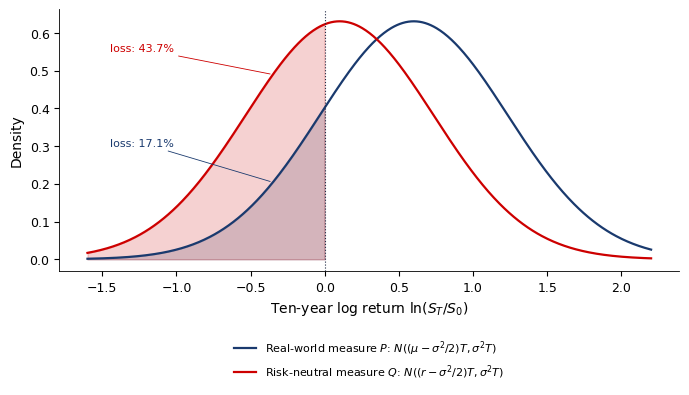

{'theta': 0.25,
 'mP': 0.06,
 'mQ': 0.01,
 'zP': np.float64(-0.9487),
 'zQ': np.float64(-0.1581),
 'p_loss_P': np.float64(0.1714),
 'p_loss_Q': np.float64(0.4372),
 'eq_growth': np.float64(1.3499),
 'var_Z': np.float64(0.8682)}

In [ ]:
# Rezolvare
def a1_girsanov(mu=0.08, sigma=0.20, r=0.03, T=10.0):
    """A4: GBM under P and under Q: the market price of risk theta = (mu - r) / sigma, the Radon-Nikodym density,
    the probability of a loss after T years under the two measures."""
    th = (mu - r) / sigma
    mP, mQ = mu - 0.5 * sigma ** 2, r - 0.5 * sigma ** 2
    return dict(theta=th, mP=mP, mQ=mQ, zP=-mP * np.sqrt(T) / sigma, zQ=-mQ * np.sqrt(T) / sigma,
                p_loss_P=stats.norm.cdf(-mP * np.sqrt(T) / sigma), p_loss_Q=stats.norm.cdf(-mQ * np.sqrt(T) / sigma),
                eq_growth=np.exp(r * T), var_Z=np.exp(th ** 2 * T) - 1)


def chart_a1_pq(mu=0.08, sigma=0.20, r=0.03, T=10.0):
    """A4: densities of ln(S_T/S_0) under P and under Q, with the loss regions (ln(S_T/S_0) < 0) hatched."""
    mP, mQ = mu - 0.5 * sigma ** 2, r - 0.5 * sigma ** 2
    x = np.linspace(-1.6, 2.2, 600)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for m, col, lab in [(mP, MainBlue, r'Real-world measure $P$: $N((\mu - \sigma^2/2)T, \sigma^2 T)$'),
                        (mQ, IDAred, r'Risk-neutral measure $Q$: $N((r - \sigma^2/2)T, \sigma^2 T)$')]:
        f = stats.norm.pdf(x, m * T, sigma * np.sqrt(T))
        ax.plot(x, f, color=col, lw=1.6, label=lab)
        ax.fill_between(x[x <= 0], f[x <= 0], color=col, alpha=0.18)
        p = stats.norm.cdf(-m * T / (sigma * np.sqrt(T)))
        ax.annotate(f'loss: {100 * p:.1f}%', xy=(-0.35, stats.norm.pdf(-0.35, m * T, sigma * np.sqrt(T))),
                    xytext=(-1.45, 0.55 if col == IDAred else 0.3), color=col, fontsize=8, bbox=dict(facecolor='white', edgecolor='none', pad=1.5),
                    arrowprops=dict(arrowstyle='-', color=col, lw=0.6))
    ax.axvline(0, color=Gray, lw=0.8, ls=':')
    ax.set_xlabel(r'Ten-year log return $\ln(S_T/S_0)$')
    ax.set_ylabel('Density')
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    save_fig('ch11_sem_a4_pq')


chart_a1_pq()
{k: round(v, 4) for k, v in a1_girsanov().items()}

### A5. Paradoxul lui Siegel și activul de referință [Propus]

Un numeraire este valoarea strict pozitivă a unui activ tranzacționat și autofinanțat, ales ca unitate de cont. Sub măsura lui de evaluare, valorile portofoliilor autofinanțate împărțite la acesta sînt martingale, sub ipotezele uzuale de integrabilitate; dividendele trebuie reinvestite sau incluse în cîștiguri.
<a id="exercise-a5"></a>

- **Întrebarea**: dacă cursul EUR/RON (lei pentru un euro) urmează GBM, este driftul RON/EUR (euro pentru un leu) pur și simplu opusul?

- **Date de intrare**: $X_t$ = lei pentru un euro, GBM cu $\mu = 2\%$, $\sigma = 4{,}4\%$ sub $P$; $Y_t = 1/X_t$; pentru pașii 3–4: rate constante $r_{RON}$, $r_{EUR}$ (simbolice), conturile monetare $B^{RON}_t = e^{r_{RON}t}$ în lei și $B^{EUR}_t = e^{r_{EUR}t}$ în euro, care valorează $X_t B^{EUR}_t$ lei; cifre date, fără date de piață

- **Sarcini**

  1.  Aplicați lema lui Itô pentru $f(x) = 1/x$ și scrieți $\mathrm{d} Y_t$.

  2.  Calculați driftul procentual al lui $Y$ cu patru zecimale și comparați-l cu $-\mu$; apoi comparați drifturile logaritmice ale lui $X$ și $Y$.

  3.  Arătați că $F = X_0 e^{(r_{RON} - r_{EUR})T} = \mathbb{E}^{Q^{RON}}[X_T]$, folosind faptul că $X_t B^{EUR}_t/B^{RON}_t$ este o $Q^{RON}$-martingală.

  4.  Opțional: cu densitatea de schimbare a activului de referință $\mathrm{d} Q^{EUR}/\mathrm{d} Q^{RON} = X_T B^{EUR}_T/(X_0 B^{RON}_T)$, arătați că $\mathbb{E}^{Q^{EUR}}[1/X_T] = 1/F$.

- **Raportați**: drifturile și cele două valori așteptate

- **Interpretare**: de ce nu există arbitraj cînd atît un investitor în lei, cît și unul în euro par să aștepte un cîștig?

- Model: [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A4); Notebook: secțiunea [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A5)

[Exercise A5 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A5)

In [ ]:
# Codul vostru aici


### A6. Obligațiunea Vasicek prin Feynman–Kac [Rezolvat]
<a id="exercise-a6"></a>

- **Întrebarea**: ce curbă a randamentelor implică azi o rată pe termen scurt Vasicek?

- **Date de intrare**: sub $Q$, $\mathrm{d} r = \kappa(\theta - r)\,\mathrm{d} t + \sigma\,\mathrm{d}\tilde W$, $\kappa = 0{,}5$, $\theta = 3\%$, $\sigma = 1\%$ (prima de risc este deja în $\theta$), $r_0 = 6\%$ [Vasicek (1977)](https://doi.org/10.1016/0304-405X(77)90016-2); o obligațiune zero-cupon plătește 1 la $T$; $p(t, r; T)$ este prețul ei, $\tau = T - t$, iar apostroful ($^{\prime}$) notează derivata $\mathrm{d}/\mathrm{d}\tau$

- **Sarcini**

  1.  Scrieți ecuația cu derivate parțiale (PDE, Partial Differential Equation) Feynman–Kac și condiția finală pentru $p(t, r; T) = \mathbb{E}^Q[e^{-\int_t^T r_s \mathrm{d} s} \mid r_t = r]$ [Kac (1949)](https://doi.org/10.1090/S0002-9947-1949-0027960-X).

  2.  Introduceți $p = \exp(A(\tau) - B(\tau)\,r)$, grupați termenii în $r$ și rezolvați pentru $B$ și $A = \int_0^\tau[-\kappa\theta B(s) + \sigma^2 B(s)^2/2]\,\mathrm{d} s$.

  3.  Calculați $y(\tau) = (B r_0 - A)/\tau$ pentru $\tau = 1, 5, 10$, limita $y_\infty$ și reprezentați curba.

- **Raportați**: $B(5)$, $A(5)$, trei randamente, $y_\infty$ și graficul

- **Interpretare**

  - de ce curba este descendentă?

  - de ce $y_\infty$ este sub $\theta$?

- Notebook: secțiunea [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A6)

1.  Feynman–Kac: $p_t + \kappa(\theta - r)p_r + \tfrac{1}{2}\sigma^2 p_{rr} - rp = 0$, $p(T, r; T) = 1$

2.  Cu $p = e^{A - Br}$ și $\partial_t = -\mathrm{d}/\mathrm{d}\tau$: $p_t = (-A' + B'r)p$, $p_r = -Bp$, $p_{rr} = B^2p$; împărțind la $p$: $-A' + B'r - \kappa(\theta - r)B + \tfrac{1}{2}\sigma^2B^2 - r = 0$ pentru orice $r$

3.  Termenii în $r$: $B' = 1 - \kappa B$, $B(0) = 0$, deci $B(\tau) = (1 - e^{-\kappa\tau})/\kappa$

4.  Constantele: $A' = -\kappa\theta B + \tfrac{1}{2}\sigma^2 B^2$; integrînd cu $\int_0^\tau B = (\tau - B)/\kappa$ și $\int_0^\tau B^2 = (\tau - B)/\kappa^2 - B^2/(2\kappa)$: $A(\tau) = \left(\theta - \frac{\sigma^2}{2\kappa^2}\right)(B - \tau) - \frac{\sigma^2B^2}{4\kappa}$





1.  $B(5) = (1 - e^{-2{,}5})/0{,}5 = 1{,}836$; $A(5) = (0{,}03 - 0{,}0002)(1{,}836 - 5) - 0{,}0001 \cdot 1{,}836^2/2 = -0{,}0945$

2.  $y(1) = 5{,}36\%$, $y(5) = 4{,}09\%$, $y(10) = 3{,}58\%$; $y_\infty = \theta - \sigma^2/(2\kappa^2) = 2{,}98\%$

- **Interpretare**: $r_0 = 6\%$ este peste $\theta$, deci ratele așteptate scad, iar curba este descendentă; $y_\infty < \theta$ din cauza convexității (Jensen): incertitudinea ratelor crește prețurile obligațiunilor și scade randamentele pe termen lung

[Exercise A6 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A6)

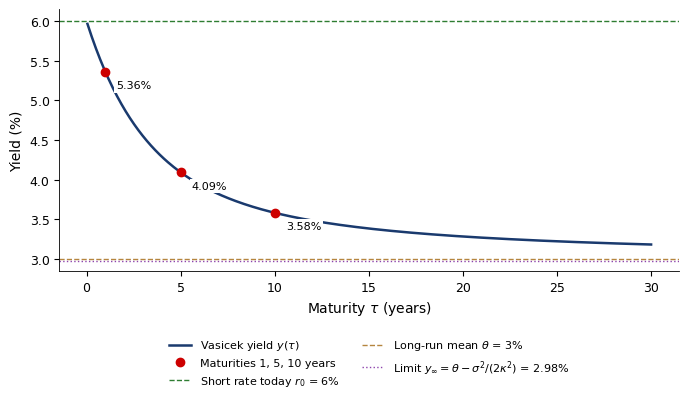

{'1': {'B': np.float64(0.7869386805747332),
  'A': np.float64(-0.006380190943222187),
  'P': np.float64(0.9478144613308426),
  'y': np.float64(0.05359651177770618)},
 '5': {'B': np.float64(1.8358300027522023),
  'A': np.float64(-0.09446077950793463),
  'P': np.float64(0.8149646184136216),
  'y': np.float64(0.040922115934613354)},
 '10': {'B': np.float64(1.986524106001829),
  'A': np.float64(-0.23899889554233184),
  'P': np.float64(0.6989400247704025),
  'y': np.float64(0.03581903419024416)},
 'y_inf': 0.0298}

In [ ]:
# Rezolvare
def a3_vasicek_bond(kappa=0.5, theta=0.03, sigma=0.01, r0=0.06, taus=(1, 5, 10)):
    """A6: Vasicek zero-coupon bond price from the Feynman-Kac equation: P = exp(A(tau) - B(tau) r)."""
    out = {}
    for tau in taus:
        B = (1 - np.exp(-kappa * tau)) / kappa
        A = (theta - sigma ** 2 / (2 * kappa ** 2)) * (B - tau) - sigma ** 2 * B ** 2 / (4 * kappa)
        out[str(tau)] = dict(B=B, A=A, P=np.exp(A - B * r0), y=(B * r0 - A) / tau)
    return dict(out, y_inf=theta - sigma ** 2 / (2 * kappa ** 2))


def chart_a3_yield(kappa=0.5, theta=0.03, sigma=0.01, r0=0.06):
    """A6: Vasicek yield curve y(tau) = (B r0 - A) / tau, with maturities 1, 5, 10 years and the limit y_inf."""
    tau = np.linspace(0.05, 30, 400)
    B = (1 - np.exp(-kappa * tau)) / kappa
    A = (theta - sigma ** 2 / (2 * kappa ** 2)) * (B - tau) - sigma ** 2 * B ** 2 / (4 * kappa)
    y = (B * r0 - A) / tau
    yinf = theta - sigma ** 2 / (2 * kappa ** 2)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(tau, 100 * y, color=MainBlue, lw=1.8, label=r'Vasicek yield $y(\tau)$')
    for t in (1, 5, 10):
        Bt = (1 - np.exp(-kappa * t)) / kappa
        At = (theta - sigma ** 2 / (2 * kappa ** 2)) * (Bt - t) - sigma ** 2 * Bt ** 2 / (4 * kappa)
        yt = (Bt * r0 - At) / t
        ax.plot(t, 100 * yt, 'o', color=IDAred, ms=6)
        ax.annotate(f'{100 * yt:.2f}%', xy=(t, 100 * yt), xytext=(8, -12), textcoords='offset points', fontsize=8, color='black', bbox=dict(facecolor='white',edgecolor='none',pad=1.5))
    ax.plot([], [], 'o', color=IDAred, label='Maturities 1, 5, 10 years')
    ax.axhline(100 * r0, color=Forest, lw=1, ls='--', label=r'Short rate today $r_0$ = 6%')
    ax.axhline(100 * theta, color=Amber, lw=1, ls='--', label=r'Long-run mean $\theta$ = 3%')
    ax.axhline(100 * yinf, color=Purple, lw=1, ls=':', label=rf'Limit $y_\infty = \theta - \sigma^2/(2\kappa^2)$ = {100 * yinf:.2f}%')
    ax.set_xlabel(r'Maturity $\tau$ (years)')
    ax.set_ylabel('Yield (%)')
    legend_outside_bottom(ax, ncol=2, y=-0.22)
    save_fig('ch11_sem_a6_yield')


chart_a3_yield()
a3_vasicek_bond()

### A2. Integrale Itô [Rezolvat]
<a id="exercise-a2"></a>

- **Întrebările**

  - ce măsoară termenul suplimentar din $\int_0^T W\,\mathrm{d} W$?

  - de ce media lui este zero?

- **Date de intrare**: o mișcare browniană standard $W$ pe $[0, T]$, $T = 1$ pentru cifre; momentele ei: [Lema lui Itô](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p6); fără date

- **Sarcini**

  1.  Aplicați lema lui Itô pentru $f(x) = x^2$ și arătați că $\int_0^T W\,\mathrm{d} W = \tfrac{1}{2}(W_T^2 - T)$.

  2.  Calculați media și dispersia acestei integrale și verificați dispersia cu izometria Itô.

  3.  Integrala Stratonovich (media capetelor) este $\tfrac{1}{2}W_T^2$: calculați-i media.

  4.  Aplicați lema lui Itô pentru $W_t^3$ și deduceți media și dispersia lui $\int_0^1 W^2\,\mathrm{d} W$.

- **Raportați**: un tabel cu integrala, media și dispersia pentru $\int W\,\mathrm{d} W$, integrala Stratonovich și $\int W^2\,\mathrm{d} W$

- **Interpretare**: de ce o integrală Itô trebuie să aibă media zero, iar integrala Stratonovich nu?

- Notebook: secțiunea [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A2)

1.  $\mathrm{d}(W^2) = 2W\,\mathrm{d} W + \mathrm{d} t$; integrînd de la 0 la $T$: $W_T^2 = 2\int_0^T W\,\mathrm{d} W + T$, deci $\int_0^T W\,\mathrm{d} W = \tfrac12(W_T^2 - T)$

2.  Media $\tfrac{1}{2}(\mathbb{E}[W_1^2] - 1) = 0$; dispersia $\tfrac{1}{4}\operatorname{Var}(W_1^2) = \tfrac{1}{4}(3 - 1) = 0{,}5$; izometria: $\int_0^1 \mathbb{E}[W_t^2]\,\mathrm{d} t = \int_0^1 t\,\mathrm{d} t = 0{,}5$

3.  Stratonovich: media $\tfrac{1}{2}\mathbb{E}[W_1^2] = 0{,}5 \neq 0$

4.  $\mathrm{d}(W^3) = 3W^2\,\mathrm{d} W + 3W\,\mathrm{d} t$; $\mathbb{E}\int_0^1 W^2\,\mathrm{d} W = 0$ și $\operatorname{Var} = \int_0^1 \mathbb{E}[W_t^4]\,\mathrm{d} t = \int_0^1 3t^2\,\mathrm{d} t = 1$

5.  Graficul (simularea din curs): stînga, $2\int_0^t W\,\mathrm{d} W + t$ coincide cu $W_t^2$; dreapta, Stratonovich minus Itô pe 5 000 de traiectorii are media $0{,}500$; sumele Itô au dispersia $0{,}520$

- **Interpretare**: integrandul Itô este fixat înaintea incrementului, deci o strategie nu poate anticipa mișcarea; media capetelor folosește mișcarea următoare și cîștigă în medie $T/2$: aceasta este variația pătratică

[Exercise A2 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A2)

In [ ]:
# Rezolvare
def a4_ito_integral(T=1.0):
    """A2: int_0^T W dW = (W_T^2 - T) / 2: mean 0, variance T^2 / 2; Stratonovich W_T^2 / 2 has mean T / 2.
    From Ito's lemma for W^3: int_0^T W^2 dW = W_T^3 / 3 - int_0^T W_t dt, with mean 0 and, by the Ito isometry,
    variance int_0^T E[W_t^4] dt = int_0^T 3 t^2 dt = T^3."""
    return dict(mean=0.0, var=T ** 2 / 2, sd=np.sqrt(T ** 2 / 2), strat_mean=T / 2, var_w2dw=T ** 3)


print(a4_ito_integral.__doc__)
a4_ito_integral(T=1.0)

A2: int_0^T W dW = (W_T^2 - T) / 2: mean 0, variance T^2 / 2; Stratonovich W_T^2 / 2 has mean T / 2.
From Ito's lemma for W^3: int_0^T W^2 dW = W_T^3 / 3 - int_0^T W_t dt, with mean 0 and, by the Ito isometry,
variance int_0^T E[W_t^4] dt = int_0^T 3 t^2 dt = T^3.


{'mean': 0.0,
 'var': 0.5,
 'sd': np.float64(0.7071067811865476),
 'strat_mean': 0.5,
 'var_w2dw': 1.0}

### A7. Cox–Ingersoll–Ross (CIR): momente condiționate și condiția Feller [Rezolvat]
<a id="exercise-a7"></a>

- **Întrebările**

  - ce valori poate lua peste un an o rată pe termen scurt CIR?

  - poate ea atinge zero?

- **Date de intrare**: procesul CIR din [Pachetele de extindere: procesul CIR și condiția Feller](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p25), cu $\kappa = 0{,}11$, $\theta = 5{,}5\%$, $\sigma = 0{,}056$ (apropiate de estimarea CIR exactă din [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2) extins) [Cox, Ingersoll & Ross (1985)](https://doi.org/10.2307/1911242); $r_0 = 3\%$, $t = 1$; tranziția $2c\,r_t \mid r_0 \sim \chi^2_\nu(\delta)$ cu $c = 2\kappa/(\sigma^2(1 - e^{-\kappa t}))$, $\nu = 4\kappa\theta/\sigma^2$, parametrul de necentralitate $\delta = 2c\,r_0 e^{-\kappa t}$

- **Sarcini**

  1.  Aplicați lema lui Itô pentru $e^{\kappa t}r_t$ și deduceți $\mathbb{E}[r_t \mid r_0]$.

  2.  Aplicați lema lui Itô pentru $r_t^2$, rezolvați ecuația pentru $m_2(t) = \mathbb{E}[r_t^2]$ cu un factor integrant și deduceți $\operatorname{Var}(r_t \mid r_0)$.

  3.  Calculați $c$, $\nu$, $\delta$ și cuantilele de 5% și 95% ale lui $r_1$ (`scipy.stats.ncx2.ppf`, apoi împărțiți la $2c$).

  4.  Arătați că $2\kappa\theta \ge \sigma^2 \Leftrightarrow \nu \ge 2$ și calculați raportul Feller.

- **Raportați**: media, abaterea standard, $c$, $\nu$, $\delta$, intervalul de predicție condiționat de 90% (nu un Confidence Interval (CI) pentru parametri), raportul Feller

- **Interpretare**: de ce intervalul este asimetric în jurul mediei?

- Notebook: secțiunea [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A7)

1.  $\mathrm{d}(e^{\kappa t}r) = \kappa\theta e^{\kappa t}\,\mathrm{d} t + \sigma e^{\kappa t}\sqrt{r}\,\mathrm{d} W$; integrala stochastică are media zero ($\mathbb{E}[r_s] < \infty$), deci $\mathbb{E}[r_t] = \theta + (r_0 - \theta)e^{-\kappa t}$

2.  $\mathrm{d}(r^2) = 2r\,\mathrm{d} r + \sigma^2 r\,\mathrm{d} t$, deci $m_2' = (2\kappa\theta + \sigma^2)\mathbb{E}[r_t] - 2\kappa m_2$; înmulțim cu $e^{2\kappa t}$ și integrăm: $m_2(t) = r_0^2e^{-2\kappa t} + (2\kappa\theta + \sigma^2)\int_0^t e^{-2\kappa(t - s)}\mathbb{E}[r_s]\,\mathrm{d} s$

3.  Scăzînd $\mathbb{E}[r_t]^2$: $\operatorname{Var} = r_0\frac{\sigma^2}{\kappa}(e^{-\kappa t} - e^{-2\kappa t}) + \frac{\theta\sigma^2}{2\kappa}(1 - e^{-\kappa t})^2$

4.  $\mathbb{E}[r_1] = 0{,}055 + (0{,}03 - 0{,}055)e^{-0{,}11} = 3{,}26\%$; abaterea standard $0{,}94\%$

1.  $c = 673$, $\nu = 7{,}72$, $\delta = 36{,}2$ (nu intensitatea salturilor); intervalul de predicție de 90% $[1{,}85\%; 4{,}92\%]$

2.  $\nu = 2 \cdot (2\kappa\theta/\sigma^2)$, deci $\nu \ge 2 \Leftrightarrow 2\kappa\theta \ge \sigma^2$; raportul Feller $3{,}86$: zero nu este atins niciodată

- **Interpretare**: volatilitatea $\sigma\sqrt{r}$ crește cu nivelul, deci legea este asimetrică la dreapta, iar banda se lărgește în sus (panoul din dreapta); ratele negative sînt imposibile, spre deosebire de Vasicek

[Exercise A7 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A7)

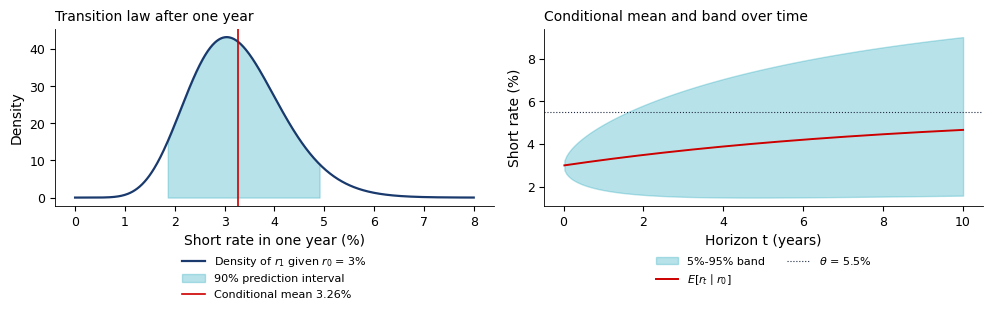

{'cmean': np.float64(0.032604146617586795),
 'csd': np.float64(0.009397705917706417),
 'c': np.float64(673.4745727325742),
 'df': 7.716836734693876,
 'nc': np.float64(36.19929069048506),
 'feller': 3.858418367346938,
 'q05': np.float64(0.018468394951652933),
 'q95': np.float64(0.04919987794192573),
 'p_below_1bp': 2.5900917429737618e-14}

In [ ]:
# Rezolvare
def a5_cir(kappa=0.11, theta=0.055, sigma=0.056, r0=0.03, t=1.0):
    """A7: CIR: conditional moments, the noncentral chi-square transition and the Feller condition (degrees of freedom >= 2)."""
    e = np.exp(-kappa * t)
    m = theta + (r0 - theta) * e
    v = r0 * sigma ** 2 / kappa * (e - e ** 2) + theta * sigma ** 2 / (2 * kappa) * (1 - e) ** 2
    c = 2 * kappa / (sigma ** 2 * (1 - e))
    df = 4 * kappa * theta / sigma ** 2
    nc = 2 * c * r0 * e
    q = stats.ncx2.ppf([0.05, 0.95], df, nc) / (2 * c)
    vas_sd = sigma * np.sqrt(r0) * np.sqrt((1 - e ** 2) / (2 * kappa))
    # P(r_t < 1 basis point); with nu >= 2 (Feller) zero is not reached, so P(r_t = 0) = 0
    return dict(cmean=m, csd=np.sqrt(v), c=c, df=df, nc=nc, feller=2 * kappa * theta / sigma ** 2, q05=q[0], q95=q[1],
                p_below_1bp=float(stats.ncx2.cdf(2 * c * 1e-4, df, nc)))


def chart_a5_cir(kappa=0.11, theta=0.055, sigma=0.056, r0=0.03):
    """A7: CIR conditional density of r_1 (noncentral chi-square / 2c) and the 5%-95% band over time."""
    def law(t):
        e = np.exp(-kappa * t)
        c = 2 * kappa / (sigma ** 2 * (1 - e))
        return c, 4 * kappa * theta / sigma ** 2, 2 * c * r0 * e
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    c, df, nc = law(1.0)
    x = np.linspace(0, 0.08, 500)
    f = stats.ncx2.pdf(2 * c * x, df, nc) * 2 * c
    q = stats.ncx2.ppf([0.05, 0.95], df, nc) / (2 * c)
    m = theta + (r0 - theta) * np.exp(-kappa)
    ax = axes[0]
    ax.plot(100 * x, f, color=MainBlue, lw=1.6, label=r'Density of $r_1$ given $r_0$ = 3%')
    ax.fill_between(100 * x, f, where=(x >= q[0]) & (x <= q[1]), color=Teal, alpha=0.3, label='90% prediction interval')
    ax.axvline(100 * m, color=IDAred, lw=1.2, label=rf'Conditional mean {100 * m:.2f}%')
    ax.set_xlabel('Short rate in one year (%)')
    ax.set_ylabel('Density')
    ax.set_title('Transition law after one year', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    ax = axes[1]
    ts = np.linspace(0.02, 10, 200)
    mt = theta + (r0 - theta) * np.exp(-kappa * ts)
    lo, hi = [], []
    for t in ts:
        c, df, nc = law(t)
        a, b = stats.ncx2.ppf([0.05, 0.95], df, nc) / (2 * c)
        lo.append(a)
        hi.append(b)
    ax.fill_between(ts, 100 * np.array(lo), 100 * np.array(hi), color=Teal, alpha=0.3, label='5%-95% band')
    ax.plot(ts, 100 * mt, color=IDAred, lw=1.4, label=r'$E[r_t \mid r_0]$')
    ax.axhline(100 * theta, color=Gray, lw=0.8, ls=':', label=r'$\theta$ = 5.5%')
    ax.set_xlabel('Horizon t (years)')
    ax.set_ylabel('Short rate (%)')
    ax.set_title('Conditional mean and band over time', loc='left')
    legend_outside_bottom(ax, ncol=2, y=-0.22)
    plt.tight_layout()
    save_fig('ch11_sem_a7_cir')


chart_a5_cir()
a5_cir()

### A8. VIX sub Heston [Propus]
<a id="exercise-a8"></a>

- **Întrebările**

  - ce parametri Heston recuperează o regresie pe pătratul VIX?

  - sub ce măsură?

- **Date de intrare**: varianța instantanee $v_t$ cu $\mathrm{d} v = \kappa^Q(\theta^Q - v)\,\mathrm{d} t + \xi_v\sqrt{v}\,\mathrm{d}\tilde W^{(2)}$ sub $Q$ și $\kappa^P$, $\theta^P$ sub $P$ (același $\xi_v$); $y_t = (\mathrm{VIX}_t/100)^2 = \frac{1}{\tau}\mathbb{E}^Q[\int_t^{t+\tau} v_s\,\mathrm{d} s \mid \mathcal{F}_t]$, $\tau = 30/365$; $\kappa^Q = 5$, $\theta^Q = 0{,}044$; o estimare CIR pe $y$ dă $\hat\xi_y = 0{,}56$

- **Sarcini**

  1.  Folosind [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A7) sub $Q$, integrați $\mathbb{E}^Q[v_s \mid v_t]$ pe $[t, t + \tau]$ și arătați că $y_t = a + b\,v_t$; calculați $b$ și $a$.

  2.  Din $\mathrm{d} y = b\,\mathrm{d} v$, scrieți difuzia lui $y$ și raportul $\xi_y/\xi_v$ ca funcție de $v$; calculați corecția locală $\hat\xi_y/b$ la $v = \theta^Q$.

  3.  Deduceți dinamica lui $y$ sub $P$ și precizați pe care dintre $\kappa^P$, $\theta^P$, $\rho$ îi recuperează o regresie istorică pe $y$ și de ce mai are nevoie $\rho$.

- **Raportați**: reproduceți deducția din [Parametrii identificați de VIX în modelul Heston](https://danpele.github.io/MFM/RO/Cursuri/capitol11_timp_continuu.pdf): $a$, $b$, corecția locală și graficul lui $\xi_y/\xi_v$. Apoi comparați $b$ la orizontul de 60 de zile cu valoarea sa la 30 de zile.

- **Interpretare**

  - este $0{,}56$ prea mare sau prea mic pentru $\xi_v$?

  - ce este necesar pentru a estima $\kappa^Q$?

- Model: [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A7); Notebook: secțiunea [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A8)

[Exercise A8 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A8)

In [ ]:
# Codul vostru aici


### A3. Merton: cumulanți și informația despre λ [Rezolvat]
<a id="exercise-a3"></a>

- **Întrebările**

  - cît de mult îndepărtează cinci salturi modeste pe an randamentele zilnice de distribuția Normală?

  - cît de precis poate fi estimat $\lambda$?

- **Date de intrare**: randamentul zilnic Merton $r_\Delta$ din [Salturi: modelul Merton](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p19); $\sigma = 15\%$, $\lambda = 5$ pe an, $\mu_J = -3\%$, $\sigma_J = 4\%$, $\Delta = 1/252$; pentru pasul 4, $T = 36{,}7$ ani

- **Sarcini**

  1.  Scrieți funcția generatoare a cumulanților $K(u) = \ln \mathbb{E}[e^{u r_\Delta}]$ și arătați că cumulanții ([Cumulanți, informația Fisher, eroarea Monte Carlo](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p21)) sînt $c_k = \lambda\Delta\,\mathbb{E}[Y^k]$ pentru $k \ge 3$.

  2.  Calculați $c_2$, separat pe difuzie și salturi, apoi $c_3$ și $c_4$.

  3.  Calculați asimetria $c_3/c_2^{3/2}$ și excesul de kurtosis $c_4/c_2^2$.

  4.  Presupuneți că fiecare salt este observat: deduceți informația Fisher a numărului Poisson $N_T$ și e.s. a lui $\hat\lambda = N_T/T$ la $\lambda = 5$; repetați la Maximum Likelihood Estimation (MLE) din curs $\hat\lambda = 101{,}9$ și comparați cu e.s. MLE $10{,}5$.

- **Raportați**: un tabel cu componentele de difuzie și de salt ale lui $c_2$, $c_3$, $c_4$, asimetria, excesul de kurtosis; cele două erori standard

- **Interpretare**: de ce e.s. a MLE este mult mai mare decît e.s. cu salturi observate?

- Notebook: secțiunea [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A3)

1.  $K(u) = u\,m\Delta + \tfrac{1}{2}u^2\sigma^2\Delta + \lambda\Delta\left(\mathbb{E}[e^{uY}] - 1\right)$; derivata de ordinul $k$ în 0 dă $c_k = \lambda\Delta\,\mathbb{E}[Y^k]$ pentru $k \ge 3$

2.  $\mathbb{E}[Y^2] = \mu_J^2 + \sigma_J^2$, $\mathbb{E}[Y^3] = \mu_J^3 + 3\mu_J\sigma_J^2$, $\mathbb{E}[Y^4] = \mu_J^4 + 6\mu_J^2\sigma_J^2 + 3\sigma_J^4$ (momentele unei variabile Normale)

3.  Înlocuim în tabelul de mai jos; asimetria $c_3/c_2^{3/2} = -2{,}07$, excesul de kurtosis $c_4/c_2^2 = 17{,}6$



|  | Difuzie | Salturi | Total |
|:---|---:|---:|---:|
| $c_2$ ($\times 10^{-4}$) | $\sigma^2\Delta = 0{,}893$ | $\lambda\Delta\mathbb{E}[Y^2] = 0{,}496$ | $1{,}389$ ($35{,}7\%$ salturi) |
| $c_3$ ($\times 10^{-6}$) | 0 | $-3{,}393$ | $-3{,}393$ |
| $c_4$ ($\times 10^{-7}$) | 0 | $3{,}399$ | $3{,}399$ |



- **Interpretare**: cinci salturi modeste pe an, o zi din 50, îndepărtează puternic randamentele zilnice de distribuția Normală; difuzia adaugă dispersie, dar nu și cumulanți de ordin superior





1.  Log-verosimilitatea numărului Poisson $\ell(\lambda) = N_T\ln\lambda - \lambda T + \mathrm{const}$, $\ell'' = -N_T/\lambda^2$; informația Fisher $I(\lambda) = -\mathbb{E}[\ell'']$, deci $I(\lambda) = \mathbb{E}[N_T]/\lambda^2 = T/\lambda$ și $\mathrm{e.s.}(\hat\lambda) = \sqrt{\lambda/T}$

2.  Scenariul 1, $\lambda = 5$: e.s. $\sqrt{5/36{,}7} = 0{,}37$, o e.s. relativă de $7{,}4\%$ (curba roșie)

3.  Scenariul 2, estimarea din curs $\hat\lambda = 101{,}9$: salturile observate ar da e.s. $1{,}67$, dar e.s. MLE este $10{,}5$, de $6{,}3$ ori mai mare

- **Interpretare**: salturile sînt latente: mixtura Poisson trebuie să le separe de mișcările difuzive, ceea ce distruge cea mai mare parte a informației despre $\lambda$; panoul din stînga arată cît de mică este partea din densitate care revine salturilor

[Exercise A3 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A3)

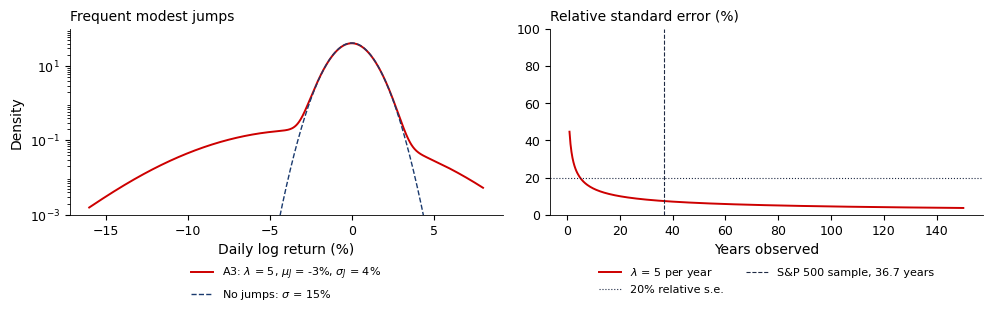

{'mean': -0.0005952380952380952, 'var': 0.00013888888888888886, 'skew': -2.0728330214211375, 'exkurt': 17.61942857142858, 'diff_var': 8.928571428571427e-05, 'jump_var': 4.96031746031746e-05, 'jump_share': 0.3571428571428572, 'k3': -3.392857142857143e-06, 'k4': 3.398809523809524e-07, 'p_jump_day': np.float64(0.019645727253408407), 'p_jump_year': np.float64(0.9932620530009145)}


{'se': np.float64(0.3691067352627811),
 'rel': np.float64(0.07382134705255622),
 'se_obs': np.float64(1.6661397895630252),
 'ratio': np.float64(6.307994122603863)}

In [ ]:
# Rezolvare
def a7_merton(sigma=0.15, lam=5.0, mu_j=-0.03, s_j=0.04, dt=1 / 252):
    """A3: cumulants of the daily Merton return."""
    mo = merton_moments(dt, sigma, lam, mu_j, s_j)
    diff_var = sigma ** 2 * dt
    jump_var = lam * dt * (mu_j ** 2 + s_j ** 2)
    return dict(mo, diff_var=diff_var, jump_var=jump_var, jump_share=jump_var / (diff_var + jump_var),
                k3=lam * dt * (mu_j ** 3 + 3 * mu_j * s_j ** 2), k4=lam * dt * (mu_j ** 4 + 6 * mu_j ** 2 * s_j ** 2 + 3 * s_j ** 4),
                p_jump_day=1 - np.exp(-lam * dt), p_jump_year=1 - np.exp(-lam))


def a7_fisher(lam=5.0, T=36.7, lam_mle=None, se_mle=None):
    """A3 (step 4): Fisher information for the Poisson intensity when jumps are observed: I(lam) = T / lam."""
    out = dict(se=np.sqrt(lam / T), rel=np.sqrt(lam / T) / lam)
    if lam_mle is not None:
        out.update(se_obs=np.sqrt(lam_mle / T), ratio=se_mle / np.sqrt(lam_mle / T))
    return out

def chart_a78_jumps(T=36.7, public=True):
    """A3: daily return density and information in observed jumps;
    relative standard error 1/sqrt(lam T) of the intensity when every jump is observed."""
    x = np.linspace(-0.16, 0.08, 800)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    ax = axes[0]
    for (lam, mj, sj), col, lab in [((5.0, -0.03, 0.04), IDAred, r'A3: $\lambda$ = 5, $\mu_J$ = -3%, $\sigma_J$ = 4%')]:
        if public and lam == 0.5: continue
        f = np.exp(merton_logpdf(x, DT, 0.0, 0.15, lam, mj, sj))
        ax.plot(100 * x, f, color=col, lw=1.4, label=lab)
    sd = 0.15 * np.sqrt(DT)
    ax.plot(100 * x, stats.norm.pdf(x, 0, sd), color=MainBlue, lw=1, ls='--', label=r'No jumps: $\sigma$ = 15%')
    ax.set_yscale('log')
    ax.set_ylim(1e-3, 100)
    ax.set_xlabel('Daily log return (%)')
    ax.set_ylabel('Density')
    ax.set_yticks([1e-3,1e-1,10])
    ax.set_title('Frequent modest jumps' if public else 'Frequent modest jumps against rare large ones', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    ax = axes[1]
    yrs = np.linspace(1, 150, 400)
    for lam, col in [(5.0, IDAred)]:
        if public and lam == 0.5: continue
        ax.plot(yrs, 100 / np.sqrt(lam * yrs), color=col, lw=1.4, label=rf'$\lambda$ = {lam:g} per year')
    ax.axhline(20, color=Gray, lw=0.8, ls=':', label='20% relative s.e.')
    ax.axvline(T, color=Gray, lw=0.8, ls='--', label='S&P 500 sample, 36.7 years')
    ax.set_ylim(0, 100)
    ax.set_xlabel('Years observed')
    ax.set_ylabel('' if public else r'Relative s.e. of $\hat\lambda$ (%)')
    ax.set_title('Relative standard error (%)' if public else 'Even with every jump observed', loc='left')
    legend_outside_bottom(ax, ncol=2, y=-0.22)
    plt.tight_layout()
    save_fig('ch11_sem_a3_jumps_public' if public else 'ch11_sem_a39_jumps')


chart_a78_jumps(public=True)
print(a7_merton())
a7_fisher(5.0, 36.7, 101.88, 10.51)

### A9. Salturi rare și mari [Propus]
<a id="exercise-a9"></a>

- **Întrebarea**: se poate estima intensitatea crahurilor rare din istoria unui singur indice?

- **Date de intrare**: modelul din [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A3) cu $\sigma = 15\%$, dar $\lambda = 0{,}5$ pe an, $\mu_J = -10\%$, $\sigma_J = 5\%$ ([A3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A3): $\lambda = 5$, $\mu_J = -3\%$, $\sigma_J = 4\%$); $\Delta = 1/252$; $T = 36{,}7$ ani; MLE din curs pentru S&P 500: $\hat\lambda = 101{,}9$

- **Sarcini**

  1.  Completați tabelul din [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A3) (componentele de difuzie și de salt ale lui $c_2$, $c_3$, $c_4$) pentru noii parametri și calculați asimetria și excesul de kurtosis.

  2.  Calculați probabilitatea de a nu avea niciun salt în 1 an și în 10 ani.

  3.  Cu toate crahurile observate, calculați e.s. a lui $\hat\lambda$ pe 36,7 ani și anii necesari pentru o e.s. relativă de 20%.

- **Raportați**: tabelul momentelor, cele două probabilități, e.s. și anii

- **Interpretare**

  - ce surprinde în schimb MLE din curs?

  - este problema doar de precizie sau și de incertitudine a modelului?

- Model: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A3); Notebook: secțiunea [A9](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A9)

[Exercise A9 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A9)

In [ ]:
# Codul vostru aici


### A1. De la un model Autoregressive de ordinul 1 (AR(1)) la un proces OU, cu erori standard [Rezolvat]
<a id="exercise-a1"></a>

- **Întrebarea**: cît de precis determină un eșantion lunar de 50 de ani viteza de revenire la medie?

- **Date de intrare**: un AR(1) estimat pe $n = 600$ de tranziții lunare ($T = n\Delta = 50$ de ani, $\Delta = 1/12$) ale unei rate în formă zecimală: $x_{t+1} = 0{,}0012 + 0{,}97\,x_t + \varepsilon_t$, abaterea standard a reziduurilor $\hat s_\varepsilon = 0{,}0025$; rata este un proces OU eșantionat exact, cu $b$, $a$, $s^2$ ca în [Revenirea la medie: procesul OU](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p15)

- **Sarcini**

  1.  Inversați cele trei relații pentru a obține $\kappa$, $\theta$, $\sigma$ și timpul de înjumătățire $\ln 2/\kappa$.

  2.  Folosiți $\operatorname{Var}(\hat b)$ pentru eșantioane mari și metoda delta din [Estimarea OU: Ordinary Least Squares (OLS) și metoda delta](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p17) pentru a calcula e.s. a lui $\hat\kappa$.

  3.  Construiți un interval de 95% pentru timpul de înjumătățire transformînd intervalul pentru $\kappa$ (valid doar dacă ambele capete sînt pozitive).

  4.  Păstrați $T = 50$ de ani, dar eșantionați zilnic ($\Delta = 1/252$): calculați $b$, e.s. a lui $\hat\kappa$ și limita ei $\sqrt{2\kappa/T}$.

- **Raportați**: un tabel cu parametrul, formula și valoarea; e.s. doar pentru $\hat\kappa$; intervalul pentru timpul de înjumătățire; e.s. zilnică

- **Interpretare**: face eșantionarea zilnică estimarea lui $\kappa$ mai precisă?

- Notebook: secțiunea [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A1)

1.  $\kappa = -\ln b/\Delta = -12\ln 0{,}97 = 0{,}366$; $\theta = a/(1 - b) = 0{,}0012/0{,}03 = 4{,}0\%$; $\sigma = s\sqrt{2\kappa/(1 - b^2)} = 0{,}88\%$; timpul de înjumătățire $\ln 2/\kappa = 1{,}90$ ani

2.  $\mathrm{e.s.}(\hat b) = \sqrt{(1 - 0{,}97^2)/600} = 0{,}0099$; $\partial\kappa/\partial b = -1/(b\Delta)$, deci $\mathrm{e.s.}(\hat\kappa) = 0{,}0099/(0{,}97/12) = 0{,}123$

3.  $\kappa \in [0{,}125; 0{,}606]$, ambele capete pozitive, deci timpul de înjumătățire este în $[\ln 2/0{,}606, \ln 2/0{,}125] = [1{,}14; 5{,}55]$ ani: asimetric în jurul lui $1{,}90$

4.  Zilnic: $b = e^{-\kappa/252} = 0{,}99855$, $n = 12\,600$, e.s. $0{,}121$; în general $\operatorname{Var}(\hat\kappa) \approx (e^{2\kappa\Delta} - 1)/(T\Delta) \to 2\kappa/T$, limita $0{,}121$ (graficul)

- **Interpretare**: de 21 de ori mai multe observații dau aceeași precizie: $\kappa$ este identificat de timpul calendaristic, nu de numărul de puncte; dacă intervalul pentru $\kappa$ ar atinge zero, timpul de înjumătățire ar fi nemărginit

[Exercise A1 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A1)

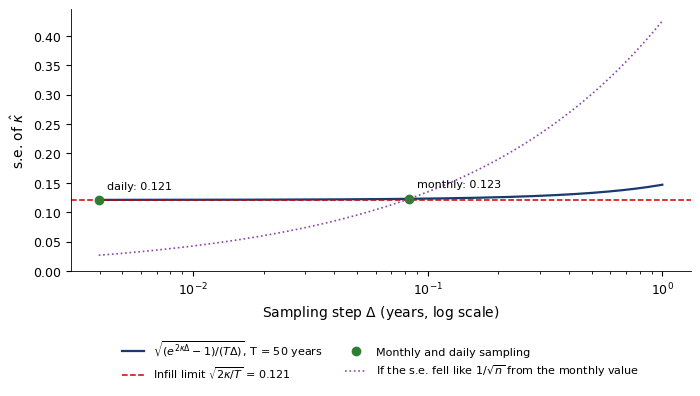

{'kappa': np.float64(0.3655104898165029),
 'theta': 0.03999999999999996,
 'sigma': np.float64(0.008792475943095903),
 'hl': np.float64(1.8963810885644505),
 'ssd': np.float64(0.010283625872371586),
 'se_b': np.float64(0.009924716620639608),
 'se_kappa': np.float64(0.12277999943059309),
 'se_hl': np.float64(0.6370204835735963),
 'T': 50.0,
 'b_daily': np.float64(0.9985506129258174),
 'se_kappa_daily': np.float64(0.12100266993602118),
 'se_kappa_limit': np.float64(0.12091492708785015)}

In [ ]:
# Rezolvare
def a9_ar_ou_delta(a=0.0012, b=0.97, se=0.0025, dt=1 / 12, n=600):
    """A1: monthly AR(1) -> OU, with delta-method standard errors; the same span T with daily data."""
    kappa = -np.log(b) / dt
    se_b = np.sqrt((1 - b ** 2) / n)
    se_k = se_b / (b * dt)
    T = n * dt
    hl = np.log(2) / kappa
    bd = np.exp(-kappa / 252)
    se_kd = np.sqrt((1 - bd ** 2) / (T * 252)) / (bd / 252)
    return dict(kappa=kappa, theta=a / (1 - b), sigma=se * np.sqrt(2 * kappa / (1 - b ** 2)), hl=hl, ssd=se / np.sqrt(1 - b ** 2),
                se_b=se_b, se_kappa=se_k, se_hl=hl / kappa * se_k, T=T, b_daily=bd, se_kappa_daily=se_kd,
                se_kappa_limit=np.sqrt(2 * kappa / T))


def chart_a9_freq(b=0.97, T=50.0):
    """A1: standard error of the estimated kappa against the sampling step, with the span T fixed."""
    kappa = -12 * np.log(b)
    dts = np.exp(np.linspace(np.log(1 / 252), np.log(1.0), 200))
    se = np.sqrt((np.exp(2 * kappa * dts) - 1) / (T * dts))
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(dts, se, color=MainBlue, lw=1.6, label=r'$\sqrt{(e^{2\kappa\Delta} - 1)/(T\Delta)}$, T = 50 years')
    ax.axhline(np.sqrt(2 * kappa / T), color=IDAred, lw=1.1, ls='--', label=rf'Infill limit $\sqrt{{2\kappa/T}}$ = {np.sqrt(2 * kappa / T):.3f}')
    for d, lab in [(1 / 12, 'monthly'), (1 / 252, 'daily')]:
        s = np.sqrt((np.exp(2 * kappa * d) - 1) / (T * d))
        ax.plot(d, s, 'o', color=Forest, ms=6)
        ax.annotate(f'{lab}: {s:.3f}', xy=(d, s), xytext=(6, 8), textcoords='offset points', fontsize=8, color='black')
    ax.plot([], [], 'o', color=Forest, label='Monthly and daily sampling')
    sm = np.sqrt((np.exp(2 * kappa / 12) - 1) / (T / 12))
    ax.plot(dts, sm * np.sqrt(dts * 12), color=Purple, lw=1.2, ls=':', label=r'If the s.e. fell like $1/\sqrt{n}$ from the monthly value')
    ax.set_xscale('log')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'Sampling step $\Delta$ (years, log scale)')
    ax.set_ylabel(r's.e. of $\hat\kappa$')
    legend_outside_bottom(ax, ncol=2, y=-0.22)
    save_fig('ch11_sem_a1_freq')


chart_a9_freq()
a9_ar_ou_delta()

## Partea B — estimare și inferență

### B4. Ordine de convergență [Rezolvat]
<a id="exercise-b4"></a>

- **Întrebările**

  - cît de repede converg schemele Euler–Maruyama și Milstein?

  - ce limitează o verificare Monte Carlo?

- **Date**: $\mathrm{d} X = 2X\,\mathrm{d} t + X\,\mathrm{d} W$, $X_0 = 1$, $T = 1$, soluția exactă $X_T = \exp(1{,}5 + W_T)$ [Higham (2001)](https://doi.org/10.1137/S0036144500378302); 20 000 de traiectorii pe o grilă fină de $2^{11}$ pași; un increment grosier este suma a $2^{11}\Delta t$ incremente fine, deci fiecare schemă și valoarea exactă folosesc aceeași traiectorie

- **Sarcini**

  1.  Pentru $\Delta t = 2^{-11}, \ldots, 2^{-5}$, salvați matricea traiectorie $\times$ pas a erorilor absolute $|X_T - X_T^{\Delta t}|$ pentru ambele scheme și calculați media pe traiectorii.

  2.  Regresați $\ln(\text{eroare})$ pe $\ln\Delta t$ (panta globală); obțineți e.s. și CI de 95% prin reeșantionarea traiectoriilor întregi, toți pașii împreună (1 000 de eșantioane).

  3.  Calculați eroarea slabă Euler–Maruyama exact, din $\mathbb{E}[X_T^{\Delta t}] = (1 + 2\Delta t)^{1/\Delta t}$, și prin media Monte Carlo; estimați ambele pante.

- **Raportați**: un tabel cu cele patru pante, cu e.s. și CI bootstrap, și graficul log-log

- **Interpretare**

  - corespund pantele ordinelor 1/2 și 1?

  - de ce eroarea slabă Monte Carlo dă o pantă greșită?

- Notebook: secțiunea [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B4)



|  | Panta globală | e.s. | 95% CI |
|:---|---:|---:|---:|
| Tare, Euler–Maruyama | $0{,}518$ | $0{,}003$ | $[0{,}512; 0{,}525]$ |
| Tare, Milstein | $0{,}986$ | $0{,}001$ | $[0{,}984; 0{,}987]$ |
| Slabă, media exactă | $0{,}985$ | – | deterministă |
| Slabă, Monte Carlo | $0{,}511$ | $0{,}269$ | $[0{,}247; 1{,}289]$ |



1.  Pantele tari globale sînt apropiate de 1/2 și 1; CI măsoară doar zgomotul Monte Carlo și pot exclude 1/2 și 1, deoarece pașii mari sînt pre-asimptotici

2.  Pantele locale între cei mai fini doi pași, $0{,}492$ (Euler) și $0{,}998$ (Milstein), sînt cele care se apropie de ordinele limită

3.  Slabă, media exactă: o pantă deterministă apropiată de 1 (locală $0{,}998$), fără interval de eșantionare

1.  Stînga: erorile tari, cu pantele de referință 1/2 și 1; înjumătățirea lui $\Delta t$ înjumătățește eroarea Milstein, dar reduce eroarea Euler doar cu $1 - 2^{-1/2} = 29\%$

2.  Dreapta: e.s. Monte Carlo a mediei, $e^2\sqrt{e - 1}/\sqrt{20\,000} = 0{,}068$, depășește eroarea slabă exactă $0{,}0072$ la $2^{-11}$, deci crucile se aplatizează

3.  Pentru acest estimator direct al mediei, distingerea erorii la 95% necesită $(1{,}96 \cdot 9{,}69/0{,}0072)^2 \approx$ 6 937 381 de traiectorii

- **Interpretare**: pentru valori așteptate, mărimea eșantionului Monte Carlo, nu pasul de timp, este constrîngerea decisivă

[Exercise B4 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B4)

Graficul complementar este în [lecture notebook, Section 3](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol11_notebook_curs.ipynb).

In [ ]:
# Rezolvare
def b1_convergence():
    """B4: orders of convergence estimated by log-log regression, with 95% confidence intervals."""
    rng = np.random.default_rng(SEED + 4)
    d, P = convergence_study(rng, return_paths=True)
    rb = np.random.default_rng(SEED + 40)
    # whole-path bootstrap intervals: the 20,000 paths are resampled, all step sizes together
    se = slope_boot(d['dt'], P['abs_em'], rb)
    sm = slope_boot(d['dt'], P['abs_mil'], rb)
    wm = slope_boot(d['dt'], P['x_em'], rb, target=P['ex'])
    # exact mean (1 + 2 dt)^{1/dt}: deterministic error, slope on the grid without a confidence interval
    x = np.log(d['dt'].values)
    we = dict(slope=float(np.polyfit(x, np.log(d['weak_em_exact']), 1)[0]),
              slope_fine=float((np.log(d['weak_em_exact'].iloc[1]) - np.log(d['weak_em_exact'].iloc[0])) / (x[1] - x[0])))
    # local slopes of the strong errors between the two finest steps (pre-asymptotic curvature)
    se['slope_fine'] = float((np.log(d['strong_em'].iloc[1]) - np.log(d['strong_em'].iloc[0])) / (x[1] - x[0]))
    sm['slope_fine'] = float((np.log(d['strong_mil'].iloc[1]) - np.log(d['strong_mil'].iloc[0])) / (x[1] - x[0]))
    x_sd = np.exp(2.0) * np.sqrt(np.exp(1.0) - 1)            # standard deviation of X_T (lam = 2, mu = 1, T = 1)
    w_small = float(d['weak_em_exact'].iloc[0])
    return dict(em=se, mil=sm, weak=we, weak_mc=wm, x_sd=x_sd, se_mc=x_sd / np.sqrt(20000),
                weak_small=w_small, m_needed=(1.96 * x_sd / w_small) ** 2, dt_small=float(d['dt'].iloc[0]))


b1_convergence()

{'em': {'slope': 0.5183286499303524,
  'se': 0.003321991946874146,
  'lo': 0.5115605735923489,
  'hi': 0.5246649153651018,
  'slope_fine': 0.4923313317985418},
 'mil': {'slope': 0.9857588125558807,
  'se': 0.0007801755180503702,
  'lo': 0.9843326467307023,
  'hi': 0.9873542660774578,
  'slope_fine': 0.9981088919214359},
 'weak': {'slope': 0.9851271286017868, 'slope_fine': 0.9983589944504876},
 'weak_mc': {'slope': 0.5109008149405617,
  'se': 0.26908911596546303,
  'lo': 0.24705604642825987,
  'hi': 1.289373628320944},
 'x_sd': np.float64(9.685814837659883),
 'se_mc': np.float64(0.06848905353026583),
 'weak_small': 0.0072076630501598515,
 'm_needed': np.float64(6937380.515736894),
 'dt_small': 0.00048828125}

### B1. GBM pe S&P 500 [Rezolvat]
<a id="exercise-b1"></a>

- **Întrebările**

  - ce parametru GBM poate fi determinat precis din 36 de ani de date zilnice?

  - ce ipoteză GBM nu este îndeplinită?

- **Date**: Închideri S&P 500, `GSPC.INDX` (cîmpul `close`), 2 ianuarie 1990 – 18 septembrie 2026, zile lucrătoare, fără cotații stale (neactualizate); $n = 9\,245$ randamente logaritmice zilnice, $T = 36{,}7$ ani, $\Delta t = 1/252$

- **Sarcini**

  1.  Calculați $\hat\sigma$, $\hat m$, $\hat\mu$, erorile lor standard sub GBM și un CI de 95% pentru $m$ cu formulele din [Estimarea GBM din randamente zilnice](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p9).

  2.  Testați normalitatea cu Jarque–Bera și independența cu Ljung–Box pe $|r_t|$ (20 de laguri), ambele la 5%, și reprezentați graficul Quantile–Quantile (QQ) și Autocorrelation Function (ACF) a lui $|r_t|$.

  3.  Calculați raportul dintre dispersia sumelor pe 20 de zile fără suprapunere (blocuri de la primul randament; ultimul bloc incomplet eliminat) și de 20 de ori dispersia zilnică.

  4.  Recalculați e.s. fără GBM: formula cu excesul de kurtosis din [Estimarea GBM din randamente zilnice](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p9) și un bootstrap pe blocuri mobile ([Raportul dispersiilor și bootstrap-ul pe blocuri mobile](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p13); blocuri de 63 de zile, 999 de eșantioane).

- **Raportați**: estimările cu e.s. GBM și bootstrap (puncte procentuale), statisticile de test cu valorile critice și deciziile, două grafice

- **Interpretare**

  - ce parametru este estimat precis?

  - care este estimat imprecis?

  - mai poate fi folosit $\hat\sigma$ pentru evaluarea opțiunilor?

- Notebook: secțiunea [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1)

1.  $n = 9\,245$, $T = 36{,}7$: $\hat\sigma = 18{,}0\%$, $\mathrm{e.s.} = \hat\sigma/\sqrt{2n} = 0{,}13$ puncte procentuale (percentage points (p.p.)); $\hat m = 8{,}3\%$, $\mathrm{e.s.} = \hat\sigma/\sqrt{T} = 3{,}0$ p.p.

2.  $\hat\mu = \hat m + \hat\sigma^2/2 = 10{,}0\%$; CI GBM de 95% pentru $m$: $[2{,}5\%; 14{,}2\%]$; $\pm 1$ punct ar necesita $(1{,}96\,\hat\sigma/0{,}01)^2 =$ 1 243 de ani

3.  Fără GBM, e.s. a lui $\hat\sigma$: $0{,}34$ p.p. cu excesul de kurtosis $k = 10{,}9$; $1{,}15$ p.p. prin bootstrap pe blocuri, de $8{,}7$ ori valoarea GBM; $m$: e.s. pe blocuri $2{,}5$ p.p., CI $[3{,}5\%; 13{,}3\%]$ (graficul GBM versus bootstrap pe blocuri)

1.  Graficul QQ: cozile sînt mult dincolo de dreapta de 45 de grade; Jarque–Bera 45 805 față de valoarea critică de 5% 5,99: normalitatea este respinsă

2.  ACF a lui $|r_t|$: $0{,}27$ la lagul 1, mult în afara intervalului GBM; Ljung–Box 13 381 față de $\chi^2_{20; 0{,}95} = 31{,}4$: independența este respinsă

3.  Raportul dispersiilor $0{,}75$, sub 1: un semn descriptiv de ușoară revenire la medie a sumelor pe 20 de zile; fără incertitudine atașată, deci nu este un test

- **Interpretare**: ambele fapte stilizate din [Capitolul 1](https://danpele.github.io/MFM/RO/Cursuri/capitol1_fapte_stilizate.pdf) resping GBM; $\hat\sigma$ este o medie a unei volatilități variabile, un reper pentru evaluare, nu o calibrare





- Albastru: intervalele GBM; roșu: bootstrap pe blocuri mobile; S&P 500 ([B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1)), pe eșantionul folosit mai sus

- Volatilitatea: intervalul bootstrap este de cîteva ori mai larg decît cel GBM, dar rămîne îngust față de $\hat\sigma$; driftul: ambele intervale sînt largi

- **Interpretare**: $\sigma$ este estimat precis chiar și fără ipoteza GBM, driftul imprecis sub orice metodă: o problemă de orizont lung

[Exercise B1 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1)

Graficul complementar este în [lecture notebook, Section 4](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol11_notebook_curs.ipynb).

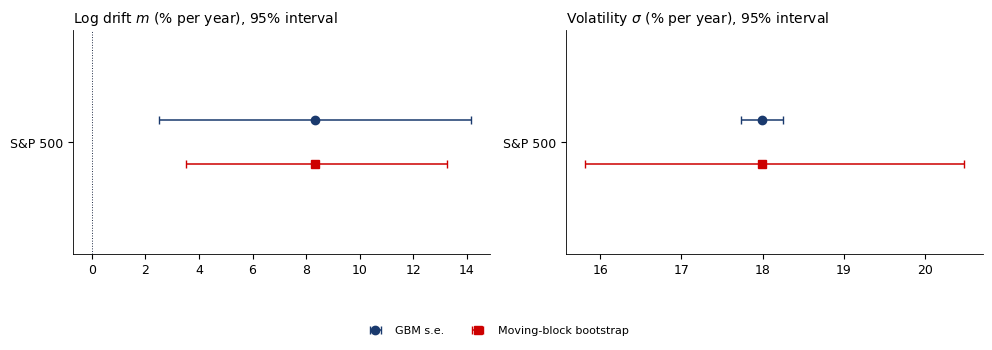

{'n': 9245,
 'years': 36.68650793650794,
 'sigma': np.float64(0.1799064408184303),
 'se_sigma': np.float64(0.0013230560900477368),
 'm': np.float64(0.0833353705968175),
 'se_m': np.float64(0.029702535554660178),
 'mu': np.float64(0.09951853432079519),
 'm_lo': np.float64(0.025118400909683557),
 'm_hi': np.float64(0.14155234028395144),
 'jb': 45805.039744069014,
 'se_sigma_kurt': 0.0033575785001281576,
 'se_sigma_block': 0.011519470973904777,
 'se_m_block': 0.025252393516043484,
 'm_lo_block': 0.03496367623103997,
 'm_hi_block': 0.13253283241595737,
 's_lo_block': 0.1581520381139075,
 's_hi_block': 0.20478477697267916,
 'jb_p': 0.0,
 'lb': 13380.997675998944,
 'lb_crit': 31.410432844230918,
 'acf1': 0.27416657507228154,
 'years_1pp': 1243.3848352406528,
 'start': '1990-01-03',
 'vr20': 0.7535748756025278,
 'exkurt': 10.880295709484036}

In [ ]:
# Rezolvare
def block_bootstrap_gbm(r, dt, block=63, n_boot=999, rng=None):
    """Moving-block bootstrap for sigma and the log drift m (the GBM estimators), without the i.i.d. assumption."""
    r = np.asarray(r)
    n = len(r)
    nb = int(np.ceil(n / block))
    starts_max = n - block + 1
    m, s = np.empty(n_boot), np.empty(n_boot)
    for i in range(n_boot):
        idx = (rng.integers(0, starts_max, nb)[:, None] + np.arange(block)[None, :]).ravel()[:n]
        x = r[idx]
        m[i] = x.mean() / dt
        s[i] = np.sqrt(x.var() / dt)
    return m, s


def b2_gbm(key='sp500'):
    """B1/B3: GBM on data: estimates with standard errors, Jarque-Bera test, Ljung-Box test on |r|, years needed."""
    r = rets[key]
    dt = DTS[key]
    g = gbm_mle(r.values, dt)
    jb = stats.jarque_bera(r.values)
    a = np.abs(r.values) - np.abs(r.values).mean()
    n = len(a)
    ac = np.array([a[k:] @ a[:-k] / (a @ a) for k in range(1, 21)])
    lb = n * (n + 2) * np.sum(ac ** 2 / (n - np.arange(1, 21)))
    q20 = [r.values[i:i + 20].sum() for i in range(0, n - 19, 20)]
    vr = np.var(q20) / (20 * r.var())
    # standard errors without the GBM assumption: (i) kurtosis-robust s.e.(sigma) for independent returns,
    # sigma sqrt((k + 2) / (4n)), k = excess kurtosis; (ii) moving-block bootstrap (Kunsch, 1989), blocks of
    # 63 days (one quarter), which keeps volatility clustering and autocorrelation
    k = float(stats.kurtosis(r.values))
    se_s_kurt = g['sigma'] * np.sqrt((k + 2) / (4 * n))
    bm, bs = block_bootstrap_gbm(r.values, dt, block=63, n_boot=999, rng=np.random.default_rng(SEED + 30))
    return dict(g, m_lo=g['m'] - 1.96 * g['se_m'], m_hi=g['m'] + 1.96 * g['se_m'], jb=float(jb.statistic),
                se_sigma_kurt=float(se_s_kurt), se_sigma_block=float(bs.std()), se_m_block=float(bm.std()),
                m_lo_block=float(np.quantile(bm, 0.025)), m_hi_block=float(np.quantile(bm, 0.975)),
                s_lo_block=float(np.quantile(bs, 0.025)), s_hi_block=float(np.quantile(bs, 0.975)),
                jb_p=float(jb.pvalue), lb=float(lb), lb_crit=float(stats.chi2.ppf(0.95, 20)), acf1=float(ac[0]),
                years_1pp=float((1.96 * g['sigma'] / 0.01) ** 2), start=str(r.index[0].date()), vr20=float(vr),
                exkurt=float(stats.kurtosis(r.values)))


def fig_legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """A single legend for a multi-panel figure, below the figure."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            h, l = ax.get_legend_handles_labels()
            for hh, ll in zip(h, l):
                if ll not in labels and not ll.startswith('_'):
                    handles.append(hh)
                    labels.append(ll)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)

def chart_b2_intervals(S, public=True):
    """B1, B3: 95% intervals for the log drift and volatility: GBM against block bootstrap."""
    rows = [('S&P 500', S['B2'])]
    if public:
        rows = rows[:1]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    for i, (name, b) in enumerate(rows):
        y = len(rows) - 1 - i
        axes[0].errorbar(100 * b['m'], y + 0.12, xerr=[[100 * (b['m'] - b['m_lo'])], [100 * (b['m_hi'] - b['m'])]],
                         fmt='o', color=MainBlue, capsize=3, label='GBM s.e.' if i == 0 else None)
        axes[0].errorbar(100 * b['m'], y - 0.12, xerr=[[100 * (b['m'] - b['m_lo_block'])], [100 * (b['m_hi_block'] - b['m'])]],
                         fmt='s', color=IDAred, capsize=3, label='Moving-block bootstrap' if i == 0 else None)
        slo, shi = b['sigma'] - 1.96 * b['se_sigma'], b['sigma'] + 1.96 * b['se_sigma']
        axes[1].errorbar(100 * b['sigma'], y + 0.12, xerr=[[100 * (b['sigma'] - slo)], [100 * (shi - b['sigma'])]],
                         fmt='o', color=MainBlue, capsize=3)
        axes[1].errorbar(100 * b['sigma'], y - 0.12, xerr=[[100 * (b['sigma'] - b['s_lo_block'])], [100 * (b['s_hi_block'] - b['sigma'])]],
                         fmt='s', color=IDAred, capsize=3)
    for ax, t in zip(axes, [r'Log drift $m$ (% per year), 95% interval', r'Volatility $\sigma$ (% per year), 95% interval']):
        ax.set_yticks(list(range(len(rows)-1,-1,-1)))
        ax.set_yticklabels([r[0] for r in rows])
        ax.set_title(t, loc='left')
        ax.set_ylim(-0.6, len(rows)-0.4)
    axes[0].axvline(0, color=Gray, lw=0.7, ls=':')
    fig_legend_bottom(fig, *axes[0].get_legend_handles_labels(), ncol=2, y=0.0)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    save_fig('ch11_sem_b1_intervals_public')


b1_result = b2_gbm('sp500')
chart_b2_intervals({'B2': b1_result}, public=True)
b1_result

### B3. GBM pe BET și Bitcoin [Propus]

Thin trading înseamnă tranzacții rare. Prețurile înregistrate neschimbate nu sînt suficiente: trebuie deosebite alinierea calendarului, cotațiile vechi și volumul efectiv tranzacționat.
<a id="exercise-b3"></a>

- **Întrebările**

  - care piață se abate mai mult de la GBM?

  - este driftul Bitcoin semnificativ pozitiv?

- **Date**: BET (`BET`, close, 2000–2026, zile lucrătoare, $\Delta t = 1/252$, $n = 6\,670$); Bitcoin (`BTC-USD.CC`, close, 18 septembrie 2014 – 18 septembrie 2026, 7 zile din 7, $\Delta t = 1/365$, $n = 4\,384$); perioade diferite

- **Sarcini**

  1.  Pentru fiecare piață, calculați $\hat\sigma$ și $\hat m$ cu CI de 95% GBM și bootstrap pe blocuri (blocuri de 63 de observații) și anii necesari pentru $\pm 1$ punct pentru $m$.

  2.  Calculați Jarque–Bera, Ljung–Box pe $|r_t|$ (20 de laguri, 5%) și raportul dispersiilor pe 20 de observații și desenați graficele QQ și ACF.

  3.  Exprimați 20 și 63 de observații în timp calendaristic pentru fiecare piață. Comparați blocuri cu același număr de observații sau cu aceeași durată?

- **Raportați**: un tabel (rînduri: $\hat\sigma$, $\hat m$ cu ambele CI, anii, excesul de kurtosis, Jarque–Bera (JB), Ljung–Box, ACF la lagul 1, raportul dispersiilor; coloane: BET, Bitcoin) și graficele

- **Interpretare**

  - ce poate sugera un raport al dispersiilor diferit de 1 pentru BET?

  - ce v-ar mai trebui pentru a-l atribui tranzacționării rare?

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1); Notebook: secțiunea [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B3)

[Exercise B3 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B3)

In [ ]:
# Codul vostru aici


### B2. Vasicek și deplasarea vitezei de revenire la medie [Rezolvat]
<a id="exercise-b2"></a>

- **Întrebarea**: revine cu adevărat randamentul titlurilor de stat pe 3 luni la o medie, după corectarea deplasării lui $\hat\kappa$?

- **Date**: Seria FRED DTB3 (randamentul titlurilor de stat SUA pe 3 luni), zilnic, 4 ianuarie 1954 – 18 septembrie 2026, împărțită la 100 (formă zecimală); $n = 18\,170$ observații, $T = 72{,}1$ ani, $\Delta t = 1/252$

- **Sarcini**

  1.  Regresați $x_{t+1}$ pe $x_t$ prin OLS (AR(1) exact din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A1)), recuperați $\kappa$, $\theta$, $\sigma$ cu e.s. prin metoda delta, un CI de 95% pentru $\kappa$ și timpul de înjumătățire [Vasicek (1977)](https://doi.org/10.1016/0304-405X(77)90016-2).

  2.  Experimentul de deplasare: simulați 500 de traiectorii OU exacte de aceeași lungime, pornite din legea staționară, cu estimările drept valori adevărate, și reestimați $\kappa$ pe fiecare.

  3.  Calculați deplasarea (media estimărilor minus valoarea adevărată), comparați-o cu $4/T$ [Tang & Chen (2009)](https://doi.org/10.1016/j.jeconom.2008.11.001) și dați $\kappa$ corectat, cu un interval aproximativ.

  4.  Experimentul nul: simulați 500 de mersuri aleatoare ($\kappa = 0$, fără drift) de aceeași lungime, din $x_0$, cu abaterea standard estimată a reziduurilor; $p$: p-value-ul Monte Carlo din [Deplasarea lui $\hat\kappa$ și un test Monte Carlo](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p18), cu $R = 500$.

- **Raportați**: estimările cu e.s., cele două distribuții simulate și valorile corectate

- **Interpretare**

  - este revenirea la medie semnificativă înainte și după corecție?

  - ce efect are deplasarea asupra riscului de dobîndă pe scadențe lungi?

- Notebook: secțiunea [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2)

1.  $\hat b = 0{,}99960$, deci $\hat\kappa = -\ln\hat b/\Delta t = 0{,}101$ (e.s. $0{,}051$), CI Wald de 95% $[0{,}001; 0{,}202]$; $\hat\theta = 4{,}55\%$ (e.s. $1{,}55$), $\hat\sigma = 1{,}33\%$, timp de înjumătățire $6{,}8$ ani

2.  Ipoteza nulă (panoul din dreapta): sub un mers aleator, $\hat\kappa$ are media $0{,}082$, nu 0, iar cuantila de 95% este $0{,}213$; valoarea observată $0{,}101$ are $p = 0{,}287$: mersul aleator nu este respins

- **Interpretare**: CI Wald abia exclude zero, deoarece ignoră legea asimetrică a lui $\hat\kappa$ în eșantioane mici; cele trei regimuri (stînga) dau și ele estimări locale foarte diferite

1.  500 de eșantioane OU exacte de $72{,}1$ ani cu $\kappa = 0{,}101$: media $\hat\kappa = 0{,}164$ (abaterea standard $0{,}078$), deplasarea $0{,}063$, apropiată de $4/T = 0{,}055$; $78\%$ dintre estimări depășesc valoarea adevărată

2.  $\kappa$ corectat $= 0{,}101 - 0{,}063 = 0{,}039$, interval aproximativ $0{,}039 \pm 1{,}96 \cdot 0{,}078 = [-0{,}114; 0{,}192]$: conține zero, deci nu se poate raporta cu încredere un timp de înjumătățire finit

- **Interpretare**: datele sînt compatibile cu o revenire lentă, dar nu pot exclude un mers aleator; cu $\kappa^Q = \kappa$, deplasarea în sus face ca Vasicek să subestimeze riscul de dobîndă pe scadențe lungi

[Exercise B2 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2)

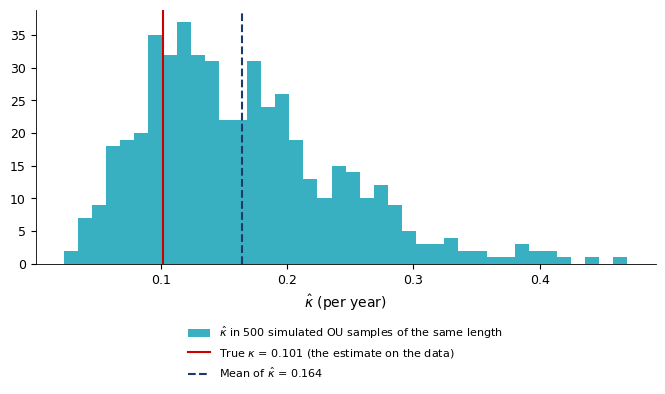

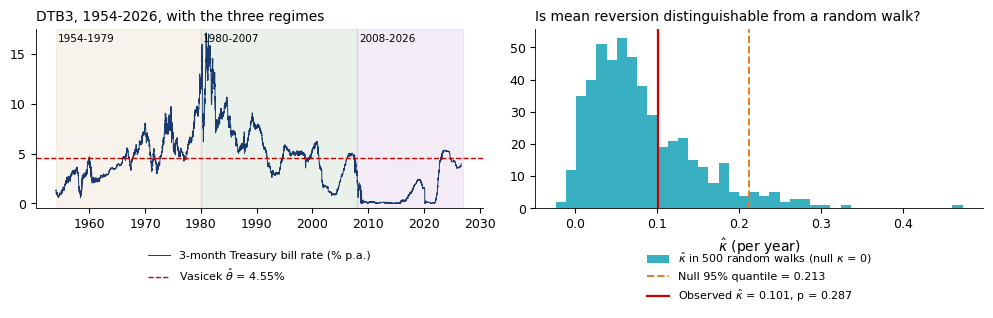

{'n': 18169,
 'a': np.float64(1.8323320445039976e-05),
 'b': np.float64(0.9995975062106393),
 'kappa': np.float64(0.10144885255529972),
 'se_kappa': 0.05144088306604999,
 'theta': np.float64(0.045524479953197854),
 'se_theta': 0.015535908651973624,
 'sigma': np.float64(0.01328825817225717),
 'half_life': np.float64(6.832479255318448),
 'se_half_life': np.float64(3.464492279323349),
 'stat_sd': np.float64(0.029500507672353026),
 'n_obs': 18170,
 'years': 72.1031746031746,
 'start': '1954-01-04',
 'k_mean': 0.1640354987261502,
 'k0_mean': 0.0817344489742041,
 'k0_q95': 0.2126516939164783,
 'p_rw': 0.2874251497005988,
 'kc_lo': -0.11400840291211287,
 'kc_hi': 0.19173281568101133,
 'resid_after_72': 0.060683196227158114,
 'k_sd': 0.07799520882477658,
 'bias': 0.06258664617085048,
 'k_corr': 0.03886220638444923,
 'hl_corr': 17.836022322121913,
 'share_above': 0.78,
 'approx_bias': 0.05547605943863512,
 'k_lo': np.float64(0.0006247217458417303),
 'k_hi': np.float64(0.20227298336475769)}

In [ ]:
# Rezolvare
def b4_vasicek(n_sim=500):
    """B2: Vasicek on the 3-month Treasury bill rate; the bias of the estimated kappa by simulation."""
    tb = read_fred('DTB3') / 100
    f = ou_mle(tb.values, DT)
    rng = np.random.default_rng(SEED + 20)
    k = ou_bias_mc(f['kappa'], f['theta'], f['sigma'], DT, len(tb), n_sim, rng)
    bias = k.mean() - f['kappa']
    kc = f['kappa'] - bias
    fig, ax = plt.subplots(figsize=(8, 3.3))
    ax.hist(k, bins=40, color=Teal, alpha=0.85, label=rf'$\hat\kappa$ in {n_sim} simulated OU samples of the same length')
    ax.axvline(f['kappa'], color=IDAred, lw=1.5, label=rf"True $\kappa$ = {f['kappa']:.3f} (the estimate on the data)")
    ax.axvline(k.mean(), color=MainBlue, lw=1.5, ls='--', label=rf'Mean of $\hat\kappa$ = {k.mean():.3f}')
    ax.set_xlabel(r'$\hat\kappa$ (per year)')
    legend_outside_bottom(ax, ncol=1, y=-0.2)
    save_fig('ch11_sem_kappa_bias')
    years = len(tb) * DT
    # inference after the correction: (i) a test of kappa = 0 (random walk, unit root) with the simulated null distribution
    # of kappa_hat (500 random walks of the same length, started at x_0, with the residual standard deviation);
    # (ii) approximate interval for the corrected kappa: kappa_c +/- 1.96 * simulated standard deviation of kappa_hat
    rw = np.random.default_rng(SEED + 24)
    sd = f['sigma'] * np.sqrt((1 - f['b'] ** 2) / (2 * f['kappa']))
    k0 = np.empty(n_sim)
    for i in range(n_sim):
        x = tb.values[0] + np.concatenate([[0.0], np.cumsum(sd * rw.standard_normal(len(tb) - 1))])
        k0[i] = -np.log(ou_mle(x, DT)['b']) / DT
    p_rw = (1 + np.sum(k0 >= f['kappa'])) / (1 + n_sim)
    return dict(f, n_obs=len(tb), years=years, start=str(tb.index[0].date()), k_mean=float(k.mean()),
                k0_mean=float(k0.mean()), k0_q95=float(np.quantile(k0, 0.95)), p_rw=float(p_rw),
                kc_lo=float(kc - 1.96 * k.std()), kc_hi=float(kc + 1.96 * k.std()),
                resid_after_72=float(np.exp(-kc * years)),
                k_sd=float(k.std()), bias=float(bias), k_corr=float(kc), hl_corr=float(np.log(2) / kc) if kc > 0 else None,
                share_above=float(np.mean(k > f['kappa'])), approx_bias=4 / years,
                k_lo=f['kappa'] - 1.96 * f['se_kappa'], k_hi=f['kappa'] + 1.96 * f['se_kappa'])


def chart_b4_null(S, n_sim=500):
    """B2: DTB3 history and the null (random-walk) distribution of the estimated kappa, with the observed value.
    Repeats the simulation of b4_vasicek (same generator SEED + 24)."""
    tb = read_fred('DTB3') / 100
    f = ou_mle(tb.values, DT)
    rw = np.random.default_rng(SEED + 24)
    sd = f['sigma'] * np.sqrt((1 - f['b'] ** 2) / (2 * f['kappa']))
    k0 = np.empty(n_sim)
    for i in range(n_sim):
        x = tb.values[0] + np.concatenate([[0.0], np.cumsum(sd * rw.standard_normal(len(tb) - 1))])
        k0[i] = -np.log(ou_mle(x, DT)['b']) / DT
    q95 = float(np.quantile(k0, 0.95))
    p = float((1 + np.sum(k0 >= f['kappa'])) / (1 + n_sim))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    ax = axes[0]
    ax.plot(tb.index, 100 * tb.values, color=MainBlue, lw=0.7, label='3-month Treasury bill rate (% p.a.)')
    for (a, b), col in zip([('1954', '1979'), ('1980', '2007'), ('2008', '2026')], [Amber, Forest, Purple]):
        ax.axvspan(pd.Timestamp(f'{a}-01-01'), pd.Timestamp(f'{b}-12-31'), color=col, alpha=0.10)
        ax.text(pd.Timestamp(f'{a}-06-01'), 16.2, f'{a}-{b}', fontsize=7.5, color='black')
    ax.axhline(100 * f['theta'], color=IDAred, lw=1, ls='--', label=rf"Vasicek $\hat\theta$ = {100 * f['theta']:.2f}%")
    ax.set_ylim(-0.5, 17.5)
    ax.set_title('DTB3, 1954-2026, with the three regimes', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.18)
    ax = axes[1]
    ax.hist(k0, bins=40, color=Teal, alpha=0.85, label=rf'$\hat\kappa$ in {n_sim} random walks (null $\kappa$ = 0)')
    ax.axvline(q95, color=Orange, lw=1.4, ls='--', label=f'Null 95% quantile = {q95:.3f}')
    ax.axvline(f['kappa'], color=IDAred, lw=1.6, label=rf"Observed $\hat\kappa$ = {f['kappa']:.3f}, p = {p:.3f}")
    ax.set_xlabel(r'$\hat\kappa$ (per year)')
    ax.set_title('Is mean reversion distinguishable from a random walk?', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.18)
    plt.tight_layout()
    save_fig('ch11_sem_b2_null')
    return dict(k0_q95=q95, p_rw=p, k0_mean=float(k0.mean()))


vasicek_result = b4_vasicek()
chart_b4_null({})
vasicek_result

### B2 Extended. CIR exact, Euler și Chan–Karolyi–Longstaff–Sanders (CKLS), 1954–2007 [Rezolvat]

Likelihood ratio (LR) compară funcțiile obiectiv restrînsă și nerestrînsă. Erorile standard Hessian folosesc curbura locală; sandwich include variabilitatea scorului, iar Heteroskedasticity and Autocorrelation Consistent (HAC) și dependența serială. Egalitatea lor cere ipoteze, nu doar o estimare reușită.
<a id="exercise-b2-extended"></a>

- **Întrebările**

  - ce specificare a volatilității preferă datele despre rata pe termen scurt?

  - în ce test putem avea încredere?

- **Date de intrare**: DTB3, 4 ianuarie 1954 – 31 decembrie 2007 (după 2008: 13 cotații exact zero, 8 negative, în afara domeniilor CIR și CKLS), zilnic ($n = 13\,487$, $\Delta = 1/252$) și la sfîrșit de lună ($n = 647$, $\Delta = 1/12$); $\kappa, \theta, \sigma > 0$

- **Sarcini**

  1.  Maximizați log-verosimilitatea CIR exactă $\sum_t [\ln(2c) + \ln f_{\chi^2_\nu(\delta_t)}(2c\,r_{t+\Delta})]$ (factorul $2c$ este jacobianul, [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A7)) și pseudo-verosimilitatea gaussiană Euler; comparați $\hat\kappa$, $\hat\theta$, cu e.s. din hessiană.

  2.  Estimați CKLS (volatilitatea $\sigma r^\gamma$, [Pachetele de extindere: procesul CIR și condiția Feller](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p25)) prin cvasi-verosimilitatea Euler; e.s. a lui $\hat\gamma$ din $H^{-1}$, sandwich $H^{-1}\Omega H^{-1}$ cu $\Omega$ produsul exterior al scorurilor și $\Omega$ Heteroskedasticity and Autocorrelation Consistent (HAC) (Bartlett, $\lfloor 4(n/100)^{2/9}\rfloor$ laguri) [Chan, Karolyi, Longstaff & Sanders (1992)](https://doi.org/10.1111/j.1540-6261.1992.tb04011.x); [Newey & West (1987)](https://doi.org/10.2307/1913610).

  3.  Testați $\gamma = 0$ și $\gamma = 1/2$ prin LR între obiectivele Euler restricționat și nerestricționat și prin teste Wald HAC, la 5% (3,84), la ambele frecvențe.

- **Raportați**: un tabel cu $\hat\kappa$ (e.s.), $\hat\theta$; $\hat\gamma$ cu trei e.s.; statisticile de test; graficul

- **Interpretare**: de ce LR și e.s. din hessiană resping prea des?

- Notebook: secțiunea [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2) Extended





| Modelul | Zilnic $\hat\kappa$ (e.s.) | Zilnic $\hat\theta$ (%) | Sfîrșit de lună $\hat\kappa$ (e.s.) | Sfîrșit de lună $\hat\theta$ (%) |
| --- | --- | --- | --- | --- |
| Vasicek, exact | $0{,}158$ ($0{,}073$) | $5{,}39$ | $0{,}201$ ($0{,}083$) | $5{,}36$ |
| CIR, exact | $0{,}113$ ($0{,}060$) | $5{,}48$ | $0{,}153$ ($0{,}070$) | $5{,}43$ |
| CIR, Euler | $0{,}093$ ($0{,}060$) | $5{,}55$ | $0{,}144$ ($0{,}069$) | $5{,}45$ |
| CKLS, Euler | $0{,}080$ ($0{,}057$) | $5{,}84$ | $0{,}144$ ($0{,}068$) | $5{,}46$ |





1.  CIR exact și Euler diferă cu mai puțin de o e.s. a lui $\hat\kappa$ la ambele frecvențe: eroarea de discretizare este mică față de incertitudinea de orizont lung

2.  Toate valorile $\hat\kappa$ sînt între 0,08 și 0,20, cu e.s. 0,06–0,08: nicio verosimilitate nu determină precis viteza (panoul din stînga al graficului de mai jos)

1.  $\hat\gamma = 0{,}77$ zilnic (e.s.: hessiană $0{,}008$, sandwich $0{,}020$, HAC $0{,}033$; $11$ laguri); $0{,}60$ lunar ($0{,}031$; $0{,}134$; $0{,}149$; $6$ laguri)

2.  $\gamma = 0$: LR $7\,926{,}6$ și $285{,}6$, Wald HAC $545{,}1$ și $16{,}1$: Vasicek respins la ambele frecvențe

3.  $\gamma = 1/2$: zilnic LR $1\,139{,}34$ și Wald HAC $67{,}01$ resping ($22{,}13$ cu $55$ laguri); lunar LR $10{,}07$ respinge, Wald HAC $0{,}45$ nu

- **Interpretare**: volatilitatea crește cu nivelul; volatility clustering omis face scorurile heteroscedastice și autocorelate, deci testul Wald HAC este cel credibil; [Chan, Karolyi, Longstaff & Sanders (1992)](https://doi.org/10.1111/j.1540-6261.1992.tb04011.x) au găsit $\hat\gamma \approx 1{,}5$ pe 1964–1989

[Exercise B2 Extended in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2)

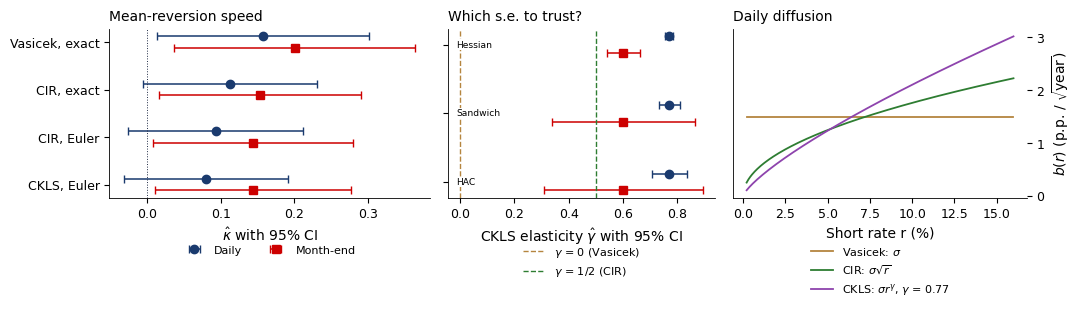

(  frequency          model   kappa  se_kappa   theta
 0     daily  vasicek_exact  0.1577    0.0735  0.0539
 1     daily  vasicek_euler  0.1577    0.0734  0.0539
 2     daily      cir_euler  0.0931    0.0603  0.0555
 3     daily      cir_exact  0.1125    0.0604  0.0548
 4     daily           ckls  0.0800    0.0566  0.0584
 5   monthly  vasicek_exact  0.2005    0.0832  0.0536
 6   monthly  vasicek_euler  0.1988    0.0818  0.0536
 7   monthly      cir_euler  0.1435    0.0691  0.0545
 8   monthly      cir_exact  0.1535    0.0701  0.0543
 9   monthly           ckls  0.1440    0.0681  0.0546,
 {'kappa': np.float64(0.08001640367962734),
  'theta': np.float64(0.0584160943190828),
  'sigma': np.float64(0.12362069119719463),
  'gamma': np.float64(0.7699284784360105),
  'se_gamma': 0.007701703987218791,
  'se_gamma_rob': 0.01965745789318536,
  'se_gamma_hac': 0.03297574258512752,
  'hac_lags': 11,
  'se_kappa': 0.05661234041631222,
  'loglik': np.float64(78778.99161516027),
  'lr_g0': np.float64

In [ ]:
# Rezolvare
def b4_likelihoods():
    """B2 Extended: exact CIR vs Euler and CKLS on DTB3, 1954-2007 (diffusion_fits of the lecture code)."""
    tb = read_fred('DTB3') / 100
    s = tb.loc['1954':'2007']
    return {'daily': short_rate_fits(s.values, DT), 'monthly': short_rate_fits(s.resample('ME').last().values, 1 / 12)}


def chart_b4x_fits(S):
    """B2 Extended: kappa with 95% CI by model and frequency, CKLS gamma with three standard errors and the fitted diffusions b(r)."""
    L4 = S['B4L']
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1.2, 1, 1.1]))
    models = [('vasicek_exact', 'Vasicek, exact'), ('cir_exact', 'CIR, exact'), ('cir_euler', 'CIR, Euler'), ('ckls', 'CKLS, Euler')]
    ax = axes[0]
    for j, (fr, col, lab) in enumerate([('daily', MainBlue, 'Daily'), ('monthly', IDAred, 'Month-end')]):
        for i, (m, _) in enumerate(models):
            k, se = L4[fr][m]['kappa'], L4[fr][m]['se_kappa']
            ax.errorbar(k, len(models) - 1 - i + (0.12 if j == 0 else -0.12), xerr=1.96 * se, fmt='o' if j == 0 else 's',
                        color=col, capsize=3, label=lab if i == 0 else None)
    ax.axvline(0, color=Gray, lw=0.7, ls=':')
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels([m[1] for m in models][::-1])
    ax.set_xlabel(r'$\hat\kappa$ with 95% CI')
    ax.set_title('Mean-reversion speed', loc='left')
    legend_outside_bottom(ax, ncol=2, y=-0.22)
    ax = axes[1]
    for j, (fr, col) in enumerate([('daily', MainBlue), ('monthly', IDAred)]):
        c = L4[fr]['ckls']
        for i, (key, lab) in enumerate([('se_gamma', 'Hessian'), ('se_gamma_rob', 'sandwich'), ('se_gamma_hac', 'HAC')]):
            ax.errorbar(c['gamma'], 2 - i + (0.12 if j == 0 else -0.12), xerr=1.96 * c[key], fmt='o' if j == 0 else 's',
                        color=col, capsize=3)
    ax.axvline(0, color=Amber, lw=1, ls='--', label=r'$\gamma$ = 0 (Vasicek)')
    ax.axvline(0.5, color=Forest, lw=1, ls='--', label=r'$\gamma$ = 1/2 (CIR)')
    ax.set_yticks([2, 1, 0])
    ax.set_yticklabels([])
    for yy, lab in zip([2,1,0], ['Hessian','Sandwich','HAC']):
        ax.text(0.03, yy, lab, transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=6.6, bbox=dict(facecolor='white',edgecolor='none',pad=0.5))
    ax.set_xlabel(r'CKLS elasticity $\hat\gamma$ with 95% CI')
    ax.set_title('Which s.e. to trust?', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    ax = axes[2]
    r = np.linspace(0.002, 0.16, 300)
    d = L4['daily']
    ax.plot(100 * r, 100 * np.full_like(r, d['vasicek_exact']['sigma']), color=Amber, lw=1.3, label=r'Vasicek: $\sigma$')
    ax.plot(100 * r, 100 * d['cir_exact']['sigma'] * np.sqrt(r), color=Forest, lw=1.3, label=r'CIR: $\sigma\sqrt{r}$')
    ax.plot(100 * r, 100 * d['ckls']['sigma'] * r ** d['ckls']['gamma'], color=Purple, lw=1.3,
            label=rf"CKLS: $\sigma r^{{\gamma}}$, $\gamma$ = {d['ckls']['gamma']:.2f}")
    ax.set_xlabel('Short rate r (%)')
    ax.set_ylabel(r'$b(r)$ (p.p. / $\sqrt{\mathrm{year}}$)')
    ax.yaxis.set_label_position('right')
    ax.yaxis.tick_right()
    ax.set_title('Daily diffusion', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    plt.tight_layout()
    save_fig('ch11_sem_b2x_fits')


L4 = b4_likelihoods()
chart_b4x_fits({'B4L': L4})
pd.DataFrame([{"frequency": f, "model": m, **{key: v.get(key) for key in ['kappa','se_kappa','theta']}} for f in L4 for m,v in L4[f].items() if isinstance(v,dict)]).round(4), L4['daily']['ckls'], L4['monthly']['ckls']

### B6. Revenirea la medie a VIX [Propus]
<a id="exercise-b6"></a>

- **Întrebările**

  - cît de repede se estompează vîrfurile de volatilitate?

  - este suficient un singur factor OU?

- **Date**: `VIX.INDX`, close, 1990–2026, zile lucrătoare; $x_t = \ln\mathrm{VIX}_t$, $\Delta t = 1/252$, $n = 9\,283$ tranziții

- **Sarcini**

  1.  Estimați procesul OU prin AR(1) exact ([B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2), pasul 1) și dați $\hat\kappa$, e.s. și nivelul median staționar $e^{\hat\theta}$.

  2.  Transformați $\hat\kappa$ în timp de înjumătățire în zile de tranzacționare, $252\ln 2/\hat\kappa$, cu intervalul $[252\ln 2/\kappa_{\mathrm{sup}}, 252\ln 2/\kappa_{\mathrm{inf}}]$ (ambele capete pozitive).

  3.  Estimați deplasarea cu 300 de traiectorii OU simulate și comparați ACF empirică cu $\hat b^k$ pînă la lagul 120, pe un grafic.

- **Raportați**: $\hat\kappa$, $e^{\hat\theta}$, timpul de înjumătățire cu interval, deplasarea, graficul ACF; reper: [Revine volatilitatea la medie? VIX](https://danpele.github.io/MFM/RO/Cursuri/capitol11_timp_continuu.pdf)

- **Interpretare**

  - la ce orizonturi nu mai este adecvat un singur factor OU?

  - ce extindere ați încerca?

- Model: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2); Notebook: secțiunea [B6](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B6)

[Exercise B6 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B6)

In [ ]:
# Codul vostru aici


### B5. Merton și un test bootstrap al raportului de verosimilitate [Rezolvat]
<a id="exercise-b5"></a>

- **Întrebarea**: resping randamentele zilnice S&P 500 modelul GBM în favoarea difuziei cu salturi Merton?

- **Date**: eșantionul S&P 500 din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1) ($n = 9\,245$ randamente logaritmice zilnice, $\Delta t = 1/252$)

- **Sarcini**

  1.  Estimați $(m, \sigma, \lambda, \mu_J, \sigma_J)$ maximizînd $\sum_t \ln f(r_t)$, cu densitatea $f$ a mixturii Poisson din [Salturi: modelul Merton](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p19) (log-sum-exp), pe $\sigma \ge 5\%$, din șase puncte de start, cu e.s. din hessiană [Merton (1976)](https://doi.org/10.1016/0304-405X(76)90022-2)

  2.  Calculați statistica raportului de verosimilitate $LR = 2(\ell_{\mathrm{Merton}} - \ell_{\mathrm{GBM}})$ pe acest spațiu restrîns ($\ell$: log-verosimilitatea maximizată; un $LR$ mare favorizează Merton).

  3.  Simulați 200 de eșantioane GBM de aceeași lungime din GBM estimat, reestimați ambele modele cu aceeași restricție și aceleași puncte de start și calculați valoarea critică de 95% și p-value-ul bootstrap din [Testul raportului de verosimilitate și frontiera](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=sem11p23) ($B = 200$).

- **Raportați**: toți cei cinci parametri cu e.s., LR, valorile critice bootstrap și $\chi^2_3$, $p$

- **Interpretare**

  - de ce $\chi^2_3$ nu este validă aici?

  - demonstrează respingerea GBM că prețurile au salturi?

- Notebook: secțiunea [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5)

1.  $\hat m = 24{,}8\%$ ($2{,}6$), $\hat\sigma = 9{,}44\%$ ($0{,}32$), $\hat\lambda = 101{,}9$ ($10{,}5$) pe an, $\hat\mu_J = -0{,}162\%$ ($0{,}034$), $\hat\sigma_J = 1{,}44\%$ ($0{,}06$); e.s. în paranteze

2.  Driftul logaritmic total este $m+\lambda\mu_J=24{,}8\%-16{,}5\%=8{,}3\%$ pe an, în acord cu estimarea GBM. Aici $m$ descrie doar componenta de difuzie.

3.  Asimetria implicată $-0{,}31$ (date $-0{,}36$), excesul de kurtosis $3{,}71$ (date $10{,}9$): densitatea estimată (graficul, stînga) urmează centrul, dar două treimi din excesul de kurtosis nu sînt reproduse

- **Interpretare**: circa 100 de „salturi” mici pe an țin locul volatilității variabile, nu al crahurilor rare

1.  LR = 2 401 (restricția $\sigma \ge 5\%$ nu este activă); valoarea critică bootstrap de 95% $5{,}62$ față de $\chi^2_{3; 0{,}95} = 7{,}81$

2.  0 din cele 200 de valori bootstrap depășesc LR, deci $\hat p = (1 + 0)/201 = 0{,}0050$, cea mai mică valoare posibilă în acest design (limita superioară Monte Carlo de 95%: $0{,}015$): GBM este respins la 5%

3.  Sub $H_0$, $\lambda = 0$ este pe frontieră, iar $\mu_J$, $\sigma_J$ nu sînt identificați: teorema lui Wilks nu se aplică, de aici bootstrapul

- **Interpretare**: testul respinge randamentele Normale i.i.d.; nu identifică traiectorii discontinue, deoarece și volatilitatea stochastică ar respinge GBM (cursul, mini studiul de caz)

[Exercise B5 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5)

Graficul complementar este în [lecture notebook, Section 8](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol11_notebook_curs.ipynb).

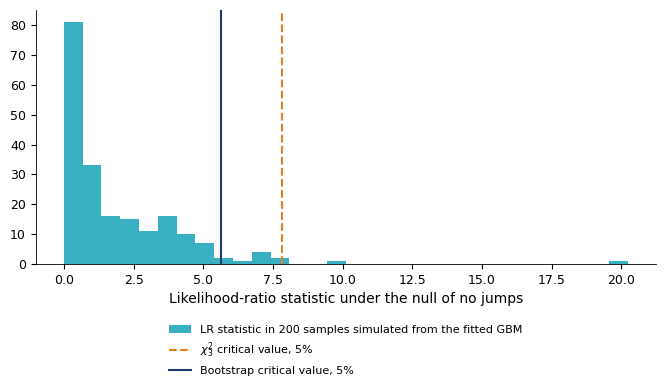

{'lr': np.float64(2400.6620623839844),
 'p_boot': 0.004975124378109453,
 'n_exceed': 0,
 'p_upper95': 0.014867039231272056,
 'sigma_min': 0.05,
 'crit95': 5.620875316648743,
 'chi2': 7.814727903251179,
 'boot_mean': 1.879224094339188,
 'boot_zero': 0.02,
 'merton': {'m': np.float64(0.24800464844720127),
  'sigma': np.float64(0.09442705609834312),
  'lam': np.float64(101.88373456232368),
  'mu_j': np.float64(-0.0016162466651812337),
  's_j': np.float64(0.014436924470693474),
  'se': {'m': np.float64(0.02590031394829748),
   'sigma': np.float64(0.0031877538072340155),
   'lam': np.float64(10.510275419239678),
   'mu_j': np.float64(0.00033558042155682307),
   's_j': np.float64(0.0006340083353040103)},
  'loglik': np.float64(29500.148269233257),
  'n': 9245},
 'moments': {'mean': np.float64(0.0003306960405739508),
  'var': np.float64(0.00012070520173746475),
  'skew': np.float64(-0.30938852670934297),
  'exkurt': np.float64(3.707205093055594)},
 'n_boot': 200}

In [ ]:
# Rezolvare
def b6_merton_lr(n_boot=200, sigma_min=0.05, n_jobs=None):
    """B5: Merton on the S&P 500: parameters with standard errors; the LR test GBM vs Merton with a parametric bootstrap.
    The statistic is defined on the restricted space sigma >= 5% (the unrestricted likelihood is unbounded, B5 Extended),
    with the same six starting points for the observed sample and for every bootstrap sample."""
    r = rets['sp500'].values
    rng = np.random.default_rng(SEED + 22)
    n_jobs = os.cpu_count() if n_jobs is None else n_jobs
    res = lr_bootstrap(r, DT, n_boot, rng, sigma_min=sigma_min, n_jobs=n_jobs)
    mf = res['merton']
    fig, ax = plt.subplots(figsize=(8, 3.3))
    ax.hist(res['boot'], bins=30, color=Teal, alpha=0.85, label=f'LR statistic in {n_boot} samples simulated from the fitted GBM')
    ax.axvline(stats.chi2.ppf(0.95, 3), color=Orange, lw=1.5, ls='--', label=r'$\chi^2_3$ critical value, 5%')
    ax.axvline(res['crit95'], color=MainBlue, lw=1.5, label='Bootstrap critical value, 5%')
    ax.set_xlabel('Likelihood-ratio statistic under the null of no jumps')
    legend_outside_bottom(ax, ncol=1, y=-0.2)
    save_fig('ch11_sem_lr_boot')
    mo = merton_moments(DT, mf['sigma'], mf['lam'], mf['mu_j'], mf['s_j'], mf['m'])
    return dict(lr=res['lr'], p_boot=res['p_boot'], n_exceed=res['n_exceed'], p_upper95=res['p_upper95'],
                sigma_min=sigma_min, crit95=res['crit95'], chi2=float(stats.chi2.ppf(0.95, 3)),
                boot_mean=float(res['boot'].mean()), boot_zero=float(np.mean(res['boot'] < 1e-6)),
                merton={k: v for k, v in mf.items()}, moments=mo, n_boot=n_boot)


res = b6_merton_lr()
res

### B5 Extended. Verosimilitatea profil în σ și verosimilitatea nemărginită [Rezolvat]
<a id="exercise-b5-extended"></a>

- **Întrebarea**: ce înseamnă MLE Merton raportat dacă verosimilitatea nu are un maxim?

- **Date de intrare**: randamentele S&P 500 și estimarea din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5) ($\hat\sigma = 9{,}4\%$); funcția de estimare din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5), cu $\sigma$ fixat [Honoré (1998)](https://doi.org/10.2139/ssrn.61998)

- **Sarcini**

  1.  Calculați log-verosimilitatea profil cu $\sigma$ fixat la 5%, 2% și 1%, reestimînd ceilalți patru parametri.

  2.  Fixați $m\Delta t$ egal cu un randament observat și lăsați $\sigma \to 0$: calculați termenul acelui randament $\ln(e^{-\lambda\Delta t}\varphi(0; 0, \sigma^2\Delta t))$ la $\sigma = 10^{-2}, 10^{-4}, 10^{-8}, 10^{-16}$.

- **Raportați**: tabelul profilului și șirul singular, cu graficul

- **Interpretare**

  - este verosimilitatea mărginită?

  - de ce profilurile numerice singure nu pot lămuri întrebarea?

- Notebook: secțiunea [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5) Extended



| $\sigma$ (fixat) | log-verosimilitatea | $\hat\lambda$ pe an | $\hat\sigma_J$ (%) |
|:---|---:|---:|---:|
| $9{,}4\%$ (MLE) | 29 500 | $101{,}9$ | $1{,}44$ |
| $5\%$ | 29 422 | $302$ | $0{,}93$ |
| $2\%$ | 29 265 | $555$ | $0{,}70$ |
| $1\%$ | 29 165 | $710$ | $0{,}62$ |



1.  Local, profilul scade cînd $\sigma$ scade, iar $\hat\lambda$ crește (panoul din stînga); MLE satisface $\sigma \ge 5\%$

2.  Global, termenul randamentului ales este $6{,}0$; $10{,}7$; $19{,}9$; $38{,}3$ la $\sigma = 10^{-2}, 10^{-4}, 10^{-8}, 10^{-16}$, iar celelalte randamente păstrează densități finite din componentele cu salturi: $\sup = +\infty$ (panoul din dreapta)

- **Interpretare**: argumentul, nu cifrele, demonstrează nemărginirea; MLE este un maxim local interior, deci testul LR din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5) este definit pe $\sigma \ge 5\%$, la fel pentru date și bootstrap

[Exercise B5 Extended in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5)

Graficul complementar este în [lecture notebook, Section 8](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol11_notebook_curs.ipynb).

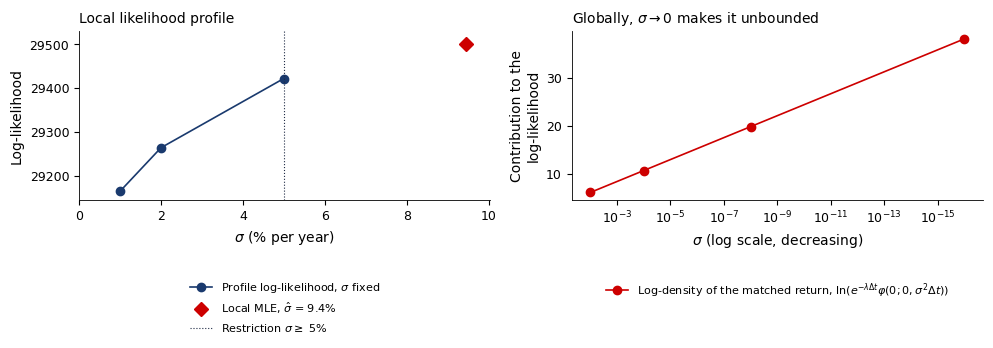

{'mle': {'sigma': np.float64(0.09442705367841887),
  'loglik': np.float64(29500.148269233257)},
 '0.05': {'loglik': np.float64(29422.456632720605),
  'lam': 302.4658534474335,
  's_j': 0.009281571664876732},
 '0.02': {'loglik': np.float64(29264.70461746258),
  'lam': 555.1212884431975,
  's_j': 0.006986623116336744},
 '0.01': {'loglik': np.float64(29165.42517470373),
  'lam': 710.0752021882466,
  's_j': 0.006174309544623829},
 'spike': {'1e-02': 6.04664563726771,
  '1e-04': 10.651815823255802,
  '1e-08': 19.862156195231982,
  '1e-16': 38.28283693918435},
 'constrained_binding': False}

In [ ]:
# Rezolvare
def b6_profile(sigmas=(0.05, 0.02, 0.01)):
    """B5 Extended: Merton profile likelihood in sigma (other parameters re-estimated) and the MLE under sigma >= 5%."""
    r = rets['sp500'].values
    mf = merton_mle(r, DT)
    out = {'mle': dict(sigma=mf['sigma'], loglik=mf['loglik'])}
    x0 = np.array([mf['m'], np.log(mf['lam']), mf['mu_j'], np.log(mf['s_j'])])
    for sg in sigmas:
        nll = lambda q, sg=sg: -merton_logpdf(r, DT, q[0], sg, np.exp(q[1]), q[2], np.exp(q[3])).sum()
        best = None
        for lam0 in (np.exp(x0[1]), 2 * np.exp(x0[1]), 4 * np.exp(x0[1])):
            q0 = x0.copy()
            q0[1] = np.log(lam0)
            res = optimize.minimize(nll, q0, method='Nelder-Mead', options=dict(maxiter=20000, maxfev=20000, xatol=1e-8, fatol=1e-6))
            if best is None or res.fun < best.fun:
                best = res
        out[f'{sg:.2f}'] = dict(loglik=-best.fun, lam=float(np.exp(best.x[1])), s_j=float(np.exp(best.x[3])))
    # sup = +infinity: sigma -> 0 with m dt equal to an observed return; the contribution of that return
    i = int(np.argmin(np.abs(r - np.median(r))))
    w0 = np.exp(-mf['lam'] * DT)
    out['spike'] = {f'{sg:.0e}': float(np.log(w0) + stats.norm.logpdf(0, 0, sg * np.sqrt(DT))) for sg in (1e-2, 1e-4, 1e-8, 1e-16)}
    out['constrained_binding'] = bool(mf['sigma'] < 0.05)
    return out


def chart_b6_profile(S):
    """B5 Extended: the log-likelihood profile in sigma and the singular term that explodes as sigma -> 0."""
    P6 = S['B6P']
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    ax = axes[0]
    sg = [P6['mle']['sigma'], 0.05, 0.02, 0.01]
    ll = [P6['mle']['loglik'], P6['0.05']['loglik'], P6['0.02']['loglik'], P6['0.01']['loglik']]
    ax.plot(100 * np.array(sg[1:]), ll[1:], 'o-', color=MainBlue, lw=1.2, label=r'Profile log-likelihood, $\sigma$ fixed')
    ax.plot(100 * sg[0], ll[0], 'D', color=IDAred, ms=7, label=rf'Local MLE, $\hat\sigma$ = {100 * sg[0]:.1f}%')
    ax.axvline(5, color=Gray, lw=0.8, ls=':', label=r'Restriction $\sigma \geq$ 5%')
    ax.set_xlabel(r'$\sigma$ (% per year)')
    ax.set_ylabel('Log-likelihood')
    ax.set_xlim(0, max(10, 100 * sg[0] + 0.6))
    ax.set_ylim(min(ll)-20, max(ll)+30)
    ax.set_title('Local likelihood profile', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.42)
    ax = axes[1]
    sp = P6['spike']
    xs = [1e-2, 1e-4, 1e-8, 1e-16]
    ys = [sp['1e-02'], sp['1e-04'], sp['1e-08'], sp['1e-16']]
    ax.plot(xs, ys, 'o-', color=IDAred, lw=1.2, label=r'Log-density of the matched return, $\ln(e^{-\lambda\Delta t}\varphi(0; 0, \sigma^2\Delta t))$')
    ax.set_xscale('log')
    ax.invert_xaxis()
    ax.set_xlabel(r'$\sigma$ (log scale, decreasing)')
    ax.set_ylabel('Contribution to the\nlog-likelihood')
    ax.set_title(r'Globally, $\sigma \to 0$ makes it unbounded', loc='left')
    legend_outside_bottom(ax, ncol=1, y=-0.42)
    plt.tight_layout()
    save_fig('ch11_sem_b5x_profile')


profile_result = b6_profile()
chart_b6_profile({'B6P': profile_result})
profile_result

### B7. Salturi în Bitcoin [Propus]
<a id="exercise-b7"></a>

- **Întrebarea**: cît de frecvente sînt salturile Bitcoin, după o mixtură estimată și după un test de detectare?

- **Date**: `BTC-USD.CC`, close, 18 septembrie 2014 – 18 septembrie 2026, 7 zile din 7, $\Delta t = 1/365$; Lee–Mykland: $L_t = r_t/\hat\sigma_t$, $\hat\sigma_t^2 = \frac{1}{K - 2}\sum_{j=t-K+2}^{t-1}|r_j|\,|r_{j-1}|$, $K = 16$; statistica $(|L_t| - C_n)/S_n$ față de $-\ln(-\ln(0{,}99))$ (formulele din curs pentru $C_n$, $S_n$) [Lee & Mykland (2008)](https://doi.org/10.1093/rfs/hhm056)

- **Sarcini**

  1.  Estimați Merton ca în [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5) și raportați toți cei cinci parametri cu e.s., excesul de kurtosis implicat și ponderea salturilor în dispersie.

  2.  Aplicați testul: primele $K - 1$ zile nu au scală locală și nu sînt testate, $n$ = numărul zilelor testate; numărați zilele marcate pe an și mărimea lor absolută medie și reprezentați randamentele și statistica.

- **Raportați**: tabelul Merton și numărul de salturi Lee–Mykland, alăturat, cu graficul; reper: [Estimarea Merton a distribuției randamentelor](https://danpele.github.io/MFM/RO/Cursuri/capitol11_timp_continuu.pdf)

- **Interpretare**

  - Comparați $\hat\lambda$ cu numărul de salturi detectate. Măsoară același lucru?

  - La trecerea la Q se pot schimba și intensitatea salturilor, și distribuția mărimii lor. De ce niciuna dintre estimări nu este direct intensitatea folosită la evaluarea opțiunii?

- Model: [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5); Notebook: secțiunea [B7](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B7)

[Exercise B7 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B7)

Constantele testului: $c=\sqrt{2/\pi}$, $C_n=\sqrt{2\ln n}/c-(\ln\pi+\ln\ln n)/(2c\sqrt{2\ln n})$, $S_n=1/(c\sqrt{2\ln n})$.

In [ ]:
# Codul vostru aici


### B8. Parametrii Heston din VIX [Propus]
<a id="exercise-b8"></a>

- **Întrebările**

  - ce spun datele S&P 500 și VIX despre $\kappa$, $\theta$, $\xi$ și $\rho$?

  - sînt acești parametri stabili?

- **Date**: S&P 500 (ca în [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1)) și `VIX.INDX` aliniate pe zilele comune, 1990–2026, apoi randamentele; $y_t = (\mathrm{VIX}_t/100)^2$ în locul lui $v_t$, $\Delta t = 1/252$ [Heston (1993)](https://doi.org/10.1093/rfs/6.2.327)

- **Sarcini**

  1.  Regresați $(y_{t+\Delta} - y_t)/\sqrt{y_t}$ pe $\Delta t/\sqrt{y_t}$ și $-\Delta t\sqrt{y_t}$ fără termen liber: $\kappa = \beta_2$, $\theta = \beta_1/\beta_2$, $\xi = s_e/\sqrt{\Delta t}$; dați e.s. OLS și HAC și un CI de 95% pentru $\kappa$.

  2.  Estimați $\rho$ drept corelația dintre $r_{t+1}/\sqrt{y_t}$ și reziduul regresiei pe același interval, cu CI Fisher-$z$ (presupune șocuri i.i.d. cu distribuție Normală bivariată), și raportul Feller $2\kappa\theta/\xi^2$.

  3.  Repetați pe 1990–2007 și 2008–2026.

- **Raportați**: un tabel cu întregul eșantion și cele două jumătăți; reper: [Parametrii Heston din VIX](https://danpele.github.io/MFM/RO/Cursuri/capitol11_timp_continuu.pdf)

- **Interpretare**: Comparați $\sqrt{\theta}$ din VIX cu volatilitatea realizată. Ce ar putea explica diferența?

- Model: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2), [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5); Notebook: secțiunea [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8)

[Exercise B8 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8)

In [ ]:
# Codul vostru aici


### B8 Extended. Corecția afină a lui ξ și ρ din varianța realizată [Propus]
<a id="exercise-b8-extended"></a>

- **Întrebarea**: depinde $\rho$ de proxy-ul varianței pe care îl folosim?

- **Date de intrare**: ca în [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8), plus varianța realizată SPDR S&P 500 Exchange-Traded Fund (ETF) Trust (SPY) la 5 minute din [Capitolul 9](https://danpele.github.io/MFM/RO/Cursuri/capitol9_volatilitate_realizata.pdf) ([`ch9_rv_spy.csv`](https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_09/ch9_rv_spy.csv)) (Realised Variance (RV) totală, inclusiv overnight, în %$^2$): anualizați prin $\mathrm{RV} \times 10^{-4}/\Delta t$; aliniați întîi S&P 500, VIX și RV pe zilele comune (octombrie 2020 – septembrie 2026), apoi randamentele

- **Sarcini**

  1.  Cu $\kappa^Q = 5$ și [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A8), calculați $b$ și corecția locală $\hat\xi/b$ și precizați ce estimări nu necesită corecție.

  2.  Pe zilele comune, estimați $\rho$ de două ori (VIX și RV în locul lui $v_t$), cu aceeași aliniere în timp a randamentelor și CI Fisher-$z$ de 95%; desenați ambele grafice de dispersie.

- **Raportați**: $\xi$ corectat, cele două corelații cu CI, graficul

- **Interpretare**

  - Comparați $\rho$ din RV și VIX. Ce ar putea explica diferența?

  - ce $\rho$ ați folosi într-un model Heston?

- Model: [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-A8), [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8); Notebook: secțiunea [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8)

[Exercise B8 Extended in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8)

In [ ]:
# Codul vostru aici


### B9. Difuzia neparametrică a randamentului titlurilor de stat [Propus]
<a id="exercise-b9"></a>

- **Întrebarea**: ce difuzie parametrică, dacă există, este compatibilă cu datele la fiecare nivel al ratei?

- **Date**: DTB3 zilnic, 1954–2007, $\Delta = 1/252$; estimările din [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2) extins [Bandi & Phillips (2003)](https://doi.org/10.1111/1468-0262.00395); grilă de 60 de niveluri între cuantilele de 2% și 98%; nucleu gaussian, $h = 1{,}06\,s_r n^{-1/5}$; ponderi $w_t(x) = K((r_t - x)/h)/\sum_s K((r_s - x)/h)$

- **Sarcini**

  1.  Calculați $\hat a(x) = \sum_t w_t\,\Delta r_t/\Delta$ și $\hat b^2(x) = \sum_t w_t\,(\Delta r_t)^2/\Delta$ cu e.s. $\sqrt{\sum_t w_t^2 (y_t - \hat m)^2}$; benzile pentru $b$ sînt rădăcinile benzilor pentru $b^2$, trunchiate la zero.

  2.  Suprapuneți difuziile Vasicek, CIR și CKLS și calculați ponderea nivelurilor aflate în banda punctuală.

  3.  Repetați cu $h/2$ și $2h$; raportați panta în logaritmi a lui $\hat b(r)$ și ponderea nivelurilor la care banda driftului conține zero.

- **Raportați**: graficul și un tabel pe lățimi de bandă

- **Interpretare**

  - se poate distinge driftul de zero?

  - ce ignoră benzile?

- Model: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2) extins; Notebook: secțiunea [B9](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B9)

[Exercise B9 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B9)

Pentru drift, $y_t=\Delta r_t/\Delta$ și $\hat m=\hat a(x)$; pentru varianță, $y_t=(\Delta r_t)^2/\Delta$ și $\hat m=\hat b^2(x)$. În lățimea de bandă, $s_r$ este abaterea standard eșantională a nivelurilor ratei.

In [ ]:
# Codul vostru aici


## Partea C — întrebări deschise

### C2. Modelul în timp continuu cel mai adecvat pentru BET și Bitcoin [Propus]
<a id="exercise-c2"></a>

- **Întrebarea**: ce fapte stilizate reproduce fiecare model estimat pe piețe fără un indice de volatilitate implicită?

- **Date**: randamentele logaritmice zilnice BET și Bitcoin (Datele folosite); proxy-ul varianței $RV_t = \frac{1}{21\Delta t}\sum_{j=0}^{20} r_{t-j}^2$, o fereastră suprapusă: pentru randamente i.i.d., autocorelația la lagul $k$ este $(21 - k)/21$, deci o parte din persistență este indusă de construcție (control: ACF simulată $0{,}952$ la lagul 1)

- **Sarcini**

  1.  Începeți cu o singură piață: estimați GBM ([B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1)), Merton ([B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5)) și Heston prin regresia din [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8), cu $RV_t$ în locul lui $v_t$.

  2.  Simulați 100 de eșantioane de lungimea datelor pentru fiecare model (Heston: Euler cu trunchiere completă, pas zilnic, $\theta$ egal cu varianța realizată, $v_0 = \theta$, 500 de pași de încălzire, sămînță fixă) și calculați excesul de kurtosis, statistica Hill $\big[\frac1k\sum_{i \le k}\ln(L_{(i)}/L_{(k+1)})\big]^{-1}$ a pierderilor $L = -r$ ($k$ = 5% din randamente), asimetria și $\sum_{k=1}^{20}$ ACF a lui $|r_t|$.

  3.  Raportați $q$ = ponderea statisticilor simulate cel mult egale cu valoarea din date (de exemplu, $q = 0{,}97$: datele sînt peste 97 din 100 de eșantioane), o verificare descriptivă, deoarece parametrii nu sînt reestimați.

- **Raportați**: medianele cu intervale de 90%, tabelul $q$, graficele; opțional: Bates (Heston plus salturi) ca proiect avansat separat

- **Interpretare**

  - Ce caracteristici nu reproduce nicio simulare? Euler zilnic menține varianța fixă în fiecare zi: asimetria aproape nulă este o limitare a discretizării, nu dovada că Heston în timp continuu nu poate produce asimetrie.

  - este Bitcoin o clasă distinctă [Pele et al. (2023)](https://doi.org/10.1080/1351847X.2021.1960403)?

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B1), [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B5), [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B8); Notebook: secțiunea [C2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-C2)

[Exercise C2 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-C2)

In [ ]:
# Codul vostru aici


### C3. Este volatilitatea SPY rough și persistentă? Etapa 1 [Propus]

Bipower Variation (BV) combină produsele valorilor absolute ale randamentelor consecutive.
<a id="exercise-c3"></a>

- **Întrebarea**: este logaritmul volatilității zilnice SPY rough ($\alpha < 0$) și în acord cu memoria lungă ($\beta < 1$)?

- **Date**: [barele SPY de 5 minute](https://raw.githubusercontent.com/danpele/MFM/main/data/market/intraday/SPY.US_5m.csv), sesiunile complete 09:30–16:00 ora New York (78 de bare); primul randament al sesiunii $\log$(close/open) al primei bare, apoi de la o închidere la alta, fără randamentul overnight; studiul de caz din curs [Bennedsen, Lunde & Pakkanen (2022)](https://doi.org/10.1093/jjfinec/nbaa049)

- **Sarcini**

  1.  Calculați variația bipower zilnică $\mathrm{BV}_t = \frac{\pi}{2}\frac{M}{M-1}\sum_{j=2}^{M}|r_j|\,|r_{j-1}|$, $M = 78$ [Barndorff-Nielsen & Shephard (2004)](https://doi.org/10.1093/jjfinec/nbh001), și logaritmul volatilității zilnice $x_t = \log\hat\sigma_t = \tfrac12\log\mathrm{BV}_t$, cu $\hat\sigma_t = \sqrt{\mathrm{BV}_t}$ în ziua $t$; reprezentați seria.

  2.  Calculați variograma $\hat\gamma_2(k) = \frac{1}{n-k}\sum_t(x_{t+k} - x_t)^2$, care se comportă ca $c\,k^{2\alpha+1}$ pentru $k$ mic; estimați $\alpha$ prin regresia OLS a lui $\log\hat\gamma_2(k)$ pe $\log k$, $k = 1, \dots, 6$, $\hat\alpha = (\text{panta} - 1)/2$, și prin Nonlinear Least Squares (NLLS) $\hat\gamma_2(k) = b_0 + b_1 k^{2\alpha+1}$, mediat pe $m = 10, \dots, 20$ laguri.

  3.  Ajustați ACF Cauchy $\rho(h) = (1 + h^{2\alpha+1})^{-\beta/(2\alpha+1)}$ și o ACF exponențială (OU) pe primele $\lceil n^{1/3}\rceil$ laguri; reprezentați-le față de ACF empirică pînă la lagul 100.

- **Raportați**: $\hat\alpha_{\mathrm{OLS}}$, $\hat\alpha^*_{\mathrm{NLLS}}$, $\hat\beta$, timpul de înjumătățire OU, trei grafice; valorile de referință în [Capitolul 11](https://danpele.github.io/MFM/RO/Cursuri/capitol11_timp_continuu.pdf)

- **Interpretare**

  - este „în acord cu memoria lungă” același lucru cu „are memorie lungă”?

  - Factorul M/(M-1) deplasează log-volatilitatea cu o constantă, care se anulează în ACF și variogramă. Cît de robuste sînt estimările la lagurile folosite?

- Model: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B2), [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-B4); Notebook: secțiunea [C3](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-C3)

- **Etapa 2, intrazilnic**: $\Delta$ = 30 și 65 de minute ($M$ = 6 și 13 randamente pe interval), $\hat\sigma^2_t = \mathrm{BV}_t/\Delta$ împărțită la un factor sezonier

  - Factorul sezonier: forma Fourier flexibilă pentru volatilitatea fiecărui interval [Andersen & Bollerslev (1997)](https://doi.org/10.1016/S0927-5398(97)00004-2), scalată astfel încît pătratul ei să aibă media 1 pe sesiune, estimată doar din date trecute; reprezentați profilul intrazilnic înainte și după

  - Lagurile $h$ și $\lambda$ sînt în pași de $\Delta$: comparați cu [Tabelul 3, Panoul A](https://doi.org/10.1093/jjfinec/nbaa049) din lucrare doar în aceeași unitate; barele în locul fiecărei tranzacții înseamnă fără pre-averaging și mai mult zgomot

- **Etapa 3, prognoză**: la $\Delta$ = 65 de minute, prognozați varianța însumată pe $h = 1, 5, 20$ pași cu log-Heterogeneous Autoregressive (HAR) (model autoregresiv heterogen pentru logaritmul volatilității) [Corsi (2009)](https://doi.org/10.1093/jjfinec/nbp001), Rough Fractional Stochastic Volatility (RFSV) [Gatheral, Jaisson & Rosenbaum (2018)](https://doi.org/10.1080/14697688.2017.1393551) și modelul Cauchy, fereastră mobilă de 200 de observații, doar cu datele pînă la fiecare origine

  - Pierderi Mean Squared Error (MSE) și Quasi-Likelihood (QLIKE), Model Confidence Set (MCS) de 90% [Hansen, Lunde & Nason (2011)](https://doi.org/10.3982/ECTA5771); reprezentați varianța realizată față de cea prognozată și diferențele cumulate QLIKE; MCS nu ordonează modelele pe care le conține

- Evaluați robustețea și reproductibilitatea, nu dacă se ating intervalele din lucrare

[Exercise C3 in the seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar11_timp_continuu_ro.pdf#nameddest=ex-C3)

In [ ]:
# Codul vostru aici
